# **DiT Generator: Generación Condicional de Caras a partir de Máscaras (Diffusion Transformer)**

## **0. Fundamento teórico y objetivos**

Este notebook entrena **desde cero** y evalúa un **Diffusion Transformer (DiT)** condicional en espacio de píxeles para generar caras RGB de $64 \times 64$ a partir de las **8 máscaras de segmentación binarias** del dataset CelebAMask-HQ (`hair`, `hat`, `l_ear`, `l_eye`, `mouth`, `nose`, `r_ear`, `r_eye`).


### **0.1 Qué es un modelo de difusión**

Un modelo de difusión aprende a generar datos **invirtiendo un proceso que los destruye poco a poco con ruido gaussiano**.

- **Proceso directo (fijo, sin parámetros).** Partiendo de una cara real $x_0$, en cada paso se añade un poco de ruido:
  $$q(x_t \mid x_{t-1}) = \mathcal{N}\!\left(x_t;\, \sqrt{1-\beta_t}\,x_{t-1},\, \beta_t \mathbf{I}\right)$$
  Con $\alpha_t = 1-\beta_t$ y $\bar{\alpha}_t = \prod_{s \le t}\alpha_s$, la propiedad reproductiva de las gaussianas permite **saltar directamente** de $x_0$ a cualquier $x_t$ en una sola operación:
  $$q(x_t \mid x_0) = \mathcal{N}\!\left(x_t;\, \sqrt{\bar{\alpha}_t}\,x_0,\, (1-\bar{\alpha}_t)\mathbf{I}\right) \quad \Longleftrightarrow \quad x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1-\bar{\alpha}_t}\,\epsilon, \qquad \epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$$

- **Número de pasos y *cosine schedule*.** Usamos $T = 1000$ pasos ($t = 0 \dots 999$). Los $\bar{\alpha}_t$ siguen el *cosine schedule* de Nichol y Dhariwal, que degrada la imagen de forma más suave que uno lineal (importante en imágenes pequeñas):
  $$\bar{\alpha}_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t/T + s}{1+s}\cdot\frac{\pi}{2}\right), \qquad s = 0.008$$
  En $t = 0$ la cara está limpia y en $t = 999$ es prácticamente ruido puro.

- **Proceso inverso (aprendido).** Una red $\epsilon_\theta$ aprende a deshacer el ruido. En lugar de predecir la imagen limpia, **predice el ruido $\epsilon$** que se añadió. Condicionada a la máscara $m$, la pérdida es un simple error cuadrático medio:
  $$\mathcal{L}(\theta) = \mathbb{E}_{x_0,\, m,\, t,\, \epsilon}\Big[\,\big\|\,\epsilon - \epsilon_\theta\big(\underbrace{\sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1-\bar{\alpha}_t}\,\epsilon}_{x_t},\; m,\; t\big)\big\|^2\Big], \qquad t \sim \mathcal{U}\{0,\dots,T-1\}$$

- **Entrenamiento frente a inferencia:**
  - *Entrenamiento:* la red **nunca recorre los 1000 pasos**. Para cada cara del batch se sortea **un único** $t$, se ensucia $x_0$ de golpe con un $\epsilon$ conocido y se minimiza el MSE entre $\epsilon$ y $\epsilon_\theta$. Es un problema de regresión estándar y estable.
  - *Inferencia:* se parte de $x_{T-1} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ y se limpia iterativamente hasta $t = 0$. Usamos **DDIM**, que estima primero la cara limpia y luego salta a un paso anterior $t_{\text{prev}}$ (lo que permite usar solo 25-100 pasos en lugar de 1000):
  $$\hat{x}_0 = \frac{x_t - \sqrt{1-\bar{\alpha}_t}\,\hat{\epsilon}}{\sqrt{\bar{\alpha}_t}}, \qquad x_{t_{\text{prev}}} = \sqrt{\bar{\alpha}_{t_{\text{prev}}}}\,\hat{x}_0 + \sqrt{1-\bar{\alpha}_{t_{\text{prev}}}-\sigma_t^2}\,\hat{\epsilon} + \sigma_t\,z$$
  donde $\sigma_t = \eta\sqrt{\tfrac{1-\bar{\alpha}_{t_{\text{prev}}}}{1-\bar{\alpha}_t}}\sqrt{1-\tfrac{\bar{\alpha}_t}{\bar{\alpha}_{t_{\text{prev}}}}}$ y $z \sim \mathcal{N}(\mathbf{0},\mathbf{I})$. Con $\eta=0$ el muestreo es determinista y con $\eta=1$ es tan estocástico como DDPM. Como el punto de partida es ruido aleatorio, **la misma máscara con distinto $x_{T-1}$ da personas distintas**.

- **Media móvil exponencial (EMA) de los pesos.** Durante el entrenamiento se mantiene una copia de los pesos que se actualiza tras cada paso:
  $$\theta_{\text{EMA}} \leftarrow d\,\theta_{\text{EMA}} + (1-d)\,\theta, \qquad d = 0.999$$
  Los pesos instantáneos oscilan por el ruido del gradiente; su media suavizada suele producir muestras más estables. Se evalúan ambos conjuntos de pesos.

### **0.2 Qué es un Vision Transformer (ViT)**

Un ViT (Dosovitskiy et al., 2021) procesa una imagen como una **secuencia de tokens** en lugar de como una rejilla de píxeles con convoluciones.

1. ***Patchify*.** La imagen $x \in \mathbb{R}^{H \times W \times C}$ se divide en parches no solapados de $P \times P$ píxeles. Cada parche se aplana (vector de $P^2 C$ valores) y se proyecta linealmente a dimensión $D$. Esto equivale a una `Conv2D(kernel=P, strides=P)`. El número de tokens es $N = \frac{H}{P}\cdot\frac{W}{P}$. Con $64 \times 64$ y $P=4$ obtenemos una rejilla de $16 \times 16$, es decir, $N = 256$ tokens.
2. **Embedding posicional.** La atención no sabe de posiciones, así que se suma a cada token un vector que codifica dónde está en la rejilla. El ViT original lo aprende. El DiT usa uno **fijo (sin-cos 2D)**: la mitad de las dimensiones codifica la fila y la otra mitad la columna con senos y cosenos de distintas frecuencias.
3. ***Self-attention* multi-cabeza.** Con $Q = ZW_Q$, $K = ZW_K$, $V = ZW_V$, cada cabeza calcula
   $$\text{Attn}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_h}}\right)V, \qquad d_h = \frac{D}{h}$$
   y las $h$ cabezas se concatenan y se proyectan con $W_O$. Cada token puede mirar a **todos** los demás ($N^2 = 65\,536$ pares): la información global está disponible desde la primera capa.
4. **Bloque Transformer (pre-norm).** Con $Z$ la secuencia de tokens:
   $$Z' = Z + \text{MHSA}\big(\text{LN}(Z)\big), \qquad Z'' = Z' + \text{MLP}\big(\text{LN}(Z')\big)$$
   El MLP es `Dense(4D) -> GELU -> Dense(D)` y `LN` es *LayerNorm*. Las conexiones residuales permiten apilar muchos bloques.

Como aquí necesitamos una **predicción densa** (un ruido por píxel), no se usa token `[CLS]`: cada token de salida se convierte de nuevo en su parche $4 \times 4 \times 3$.

### **0.3 Qué es el DiT y por qué adaLN-Zero**

El **DiT** (Peebles y Xie, 2023) usa un Transformer como predictor de ruido de un modelo de difusión. El problema es cómo informarle del **paso $t$**: la red debe comportarse de forma muy distinta si la imagen está casi limpia o casi destruida. Los autores comparan varias opciones (tokens extra, atención cruzada, LayerNorm adaptativa) y la mejor es **adaLN-Zero**.

- **LayerNorm adaptativa (adaLN).** La *LayerNorm* se usa **sin parámetros afines propios**. Su escala y desplazamiento los **genera una pequeña red a partir del embedding $c$** (aquí, el del paso $t$):
  $$\text{adaLN}(h, c) = \text{LN}(h)\odot\big(1+\gamma(c)\big) + \beta(c)$$
- **Gate (la parte "Zero").** Además de $\gamma$ y $\beta$, cada bloque produce un **gate $\alpha$** que multiplica la salida de cada subcapa *antes* de sumarla al residual. Una única `Dense` aplicada sobre $\text{SiLU}(c)$ genera los **6 vectores** por bloque:
  $$(\beta_1, \gamma_1, \alpha_1, \beta_2, \gamma_2, \alpha_2) = \text{Dense}\big(\text{SiLU}(c)\big) \in \mathbb{R}^{6D}$$
  $$h \leftarrow h + \alpha_1 \odot \text{MHSA}\big(\text{adaLN}(h; \beta_1,\gamma_1)\big), \qquad h \leftarrow h + \alpha_2 \odot \text{MLP}\big(\text{adaLN}(h; \beta_2,\gamma_2)\big)$$
- **Inicialización a cero.** Los pesos y sesgos de esa `Dense` se inicializan a $0$, de modo que $\alpha_1=\alpha_2=0$ y **cada bloque empieza siendo exactamente la identidad**. Al inicio la red completa es una función trivial y cada bloque "se activa" progresivamente a medida que aprende. Es el mismo principio que inicializar a cero la última normalización de un bloque residual en una ResNet, y los autores observan que mejora el entrenamiento frente a adaLN sin gate. La capa final (LayerNorm + modulación + `Dense` a $P^2\cdot 3$) también se inicializa a cero, así que el modelo arranca prediciendo ruido $\hat{\epsilon}=0$.
- **Por qué se usa.** Es casi gratuito en cómputo (solo un vector por bloque, sin tokens adicionales), actúa igual sobre todos los tokens y deja que el nivel de ruido module la red en **todas las profundidades**, no solo a la entrada.

> **Adaptación respecto al DiT original:** el artículo trabaja en el espacio latente de un VAE con etiquetas de clase (el embedding $c$ suma $t$ y la clase). Aquí trabajamos **directamente en píxeles** y $c$ contiene **solo el paso $t$**, porque la condición (la máscara) es espacial y entra por los tokens (ver 0.4).

### **0.4 Cómo se condiciona con la máscara**

Se aplica **exactamente el mismo mecanismo que en la U-Net**: antes del *patchify* se concatenan por canales la imagen ruidosa y la máscara one-hot:

$$z_t = \big[\,x_t \;\|\; m\,\big] \in \mathbb{R}^{64 \times 64 \times (3+8)}, \qquad m \in \{0,1\}^{64\times 64\times 8}$$

- La **máscara nunca se ensucia con ruido**: el proceso directo solo actúa sobre $x_0$ (3 canales). Los 8 canales de $m$ llegan limpios en todos los pasos $t$, y así la red siempre sabe **dónde** debe ir cada rasgo.
- El *patchify* `Conv2D(kernel=4, strides=4)` sobre estos **11 canales** convierte cada parche en un vector de $4\cdot4\cdot11 = 176$ valores proyectado a $D = 256$. Cada token recibe, por tanto, la imagen ruidosa **y** la máscara de su región. La atención global propaga después esa información al resto de la cara.
- La red devuelve $\hat{\epsilon} \in \mathbb{R}^{64\times64\times3}$ y el MSE se calcula solo contra el ruido de la imagen.
- **Reparto de roles:** el **paso $t$** entra por **adaLN-Zero** (condicionamiento global y escalar) y la **máscara** entra por los **tokens** (condicionamiento espacial y denso).

### **0.5 Diferencias con la U-Net e hipótesis de diseño**

| Aspecto | U-Net (`diffusion_generator`) | DiT (este notebook) |
|---|---|---|
| Operador principal | Convoluciones $3\times3$ (locales) | *Self-attention* global |
| Sesgo inductivo | Localidad y equivarianza a traslaciones | Mínimo (la posición solo entra por el embedding fijo) |
| Resolución interna | Jerárquica: $64 \to 32 \to 16 \to 8$ | Única: rejilla de $16\times16$ tokens |
| Flujo de información | *Skip connections* por concatenación | Corriente residual (*residual stream*) |
| Atención | Solo en $16\times16$ y $8\times8$ | En los 8 bloques |
| Condicionamiento de $t$ | FiLM (escala y desplazamiento) en cada bloque residual | adaLN-Zero (escala, desplazamiento y gate) |
| Normalización | `GroupNormalization` | `LayerNorm` |
| Parámetros | 9,4 M | Objetivo 9-10 M (el valor exacto se registra en la Sección 3) |

**Hipótesis de diseño.** Solo cambia el *backbone*. Los datos, el *split* 80/10/10, el *cosine schedule*, $T=1000$, la pérdida MSE sobre $\epsilon$, AdamW con *cosine decay*, el aumento, el DDIM y las métricas son los mismos. Con un presupuesto de parámetros similar, la pregunta es si la **atención global** compensa la falta de sesgo inductivo convolucional con solo 24.000 caras de $64\times64$.

**Salvedades (para no sobreatribuir):** el DiT añade una copia **EMA** de los pesos y no usa *dropout*, mientras que la U-Net no usa EMA y sí usa *dropout* $0.1$ en las escalas profundas. Por eso se evalúan y se registran los pesos normales y los EMA.

---

## **1. Configuración e imports**

In [6]:
import zipfile
from pathlib import Path

!pip install -q torchmetrics torch-fidelity

from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/MetodosGenerativos")
ZIP_PATH = DRIVE_PROJECT_DIR / "data.zip"
LOCAL_EXTRACT_DIR = Path("/content/dataset")

if not (LOCAL_EXTRACT_DIR / "data" / "images").is_dir() and not (LOCAL_EXTRACT_DIR / "images").is_dir():
    print("Descomprimiendo data.zip en disco local")
    LOCAL_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(LOCAL_EXTRACT_DIR)

DATA_DIR = LOCAL_EXTRACT_DIR / "data" if (LOCAL_EXTRACT_DIR / "data" / "images").is_dir() else LOCAL_EXTRACT_DIR
CHECKPOINT_DIR = DRIVE_PROJECT_DIR / "checkpoints_dit"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Colab listo | DATA_DIR={DATA_DIR} | CHECKPOINT_DIR={CHECKPOINT_DIR}")

Mounted at /content/drive
Descomprimiendo data.zip en disco local
Colab listo | DATA_DIR=/content/dataset | CHECKPOINT_DIR=/content/drive/MyDrive/MetodosGenerativos/checkpoints_dit


In [7]:
import math
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import random
import time
from pathlib import Path

import keras
from keras import layers
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from torchmetrics.image.fid import NoTrainInceptionV3, _compute_fid

try:
    from IPython.display import display
except ImportError:
    display = print

tf.get_logger().setLevel("ERROR")

In [8]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 64
EPOCHS = 100

# Difusión (DDPM + DDIM): igual que la U-Net
TIMESTEPS = 1000
COSINE_S = 0.008
LR_INIT = 2e-4
COSINE_ALPHA = 0.05
WEIGHT_DECAY = 1e-4
EMA_DECAY = 0.999

# Arquitectura DiT
PATCH_SIZE = 4      # parches de 4x4 -> rejilla de 16x16 = 256 tokens
HIDDEN_DIM = 256    # dimensión de los tokens
DEPTH = 8           # número de bloques DiT
NUM_HEADS = 4       # cabezas de atención (64 dimensiones por cabeza)
MLP_RATIO = 4       # el MLP interno tiene 4 * HIDDEN_DIM neuronas
TIME_DIM = 256      # dimensión del embedding del paso t

# Seguimiento y evaluación
VAL_FID_SAMPLES = 500
VAL_FID_EVERY = 5
VAL_DDIM_STEPS = 25
EVAL_DDIM_STEPS = 50
EVAL_DDIM_ETA = 0.0
FID_BATCH_SIZE = 64
NEW_FACES_N = 3000

# Flags
TRAIN_MODEL = False          # True: entrena (o continúa) | False: carga los checkpoints de Drive
RESUME = True               # True: continúa desde RESUME_PATH si existe | False: entrena desde cero
RUN_BENCHMARK = False       # True: ejecuta la celda de benchmark (20-30 pasos) antes de entrenar
USE_MIXED_FLOAT16 = False   # True: entrena con mixed_float16 (probar antes con el benchmark)
NOTEBOOK_NAME = "dit_generator"

# Fallback dinámico para encontrar la ruta de los datos
DATA_DIR = globals().get("DATA_DIR", Path("data"))
if not (DATA_DIR / "images").is_dir():
    # Intentar buscar en la ubicación típica de descompresión de Colab
    colab_path = Path("/content/dataset")
    if (colab_path / "data").is_dir():
        DATA_DIR = colab_path / "data"
    elif colab_path.is_dir():
        DATA_DIR = colab_path

IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"

if not IMAGES_DIR.is_dir() or not MASKS_DIR.is_dir():
    raise FileNotFoundError(
        f"Faltan 'images/' y 'masks/' en {DATA_DIR.resolve()}"
    )

CHECKPOINT_DIR = globals().get("CHECKPOINT_DIR", Path("checkpoints_dit"))
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

DIT_PATH = CHECKPOINT_DIR / "dit.keras"                    # mejores pesos normales
DIT_EMA_PATH = CHECKPOINT_DIR / "dit_ema.keras"            # mejores pesos EMA
MASK_CLASSES_PATH = CHECKPOINT_DIR / "mask_classes_dit.json"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"
RESUME_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_resume.npz"   # estado para reanudar (pesos, EMA, optimizador, época)
METRICS_CSV_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_metrics.csv"


def reset_seeds(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    torch.manual_seed(seed)


reset_seeds(SEED)

# Precisión numérica global (por defecto float32; mixed_float16 solo si se activa el flag)
keras.mixed_precision.set_global_policy("mixed_float16" if USE_MIXED_FLOAT16 else "float32")

print(f"Imágenes: {IMAGES_DIR.resolve()}")
print(f"Máscaras: {MASKS_DIR.resolve()}")
print(f"Checkpoints: {CHECKPOINT_DIR.resolve()}")
print(
    f"TRAIN_MODEL={TRAIN_MODEL} | RESUME={RESUME} | EPOCHS={EPOCHS} | T={TIMESTEPS} | "
    f"DDIM val/eval={VAL_DDIM_STEPS}/{EVAL_DDIM_STEPS} | mixed_float16={USE_MIXED_FLOAT16}"
)

Imágenes: /content/dataset/data/images
Máscaras: /content/dataset/data/masks
Checkpoints: /content/drive/MyDrive/MetodosGenerativos/checkpoints_dit
TRAIN_MODEL=False | RESUME=True | EPOCHS=100 | T=1000 | DDIM val/eval=25/50 | mixed_float16=False


In [9]:
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

INCEPTION_DEVICE = (
    "cuda" if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"TensorFlow: {gpus if gpus else 'CPU'} | InceptionV3 (PyTorch): {INCEPTION_DEVICE}")

TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | InceptionV3 (PyTorch): cuda


---

## **2. Carga de datos, máscaras One-Hot y FID**

In [10]:
mask_filenames = sorted(p.name for p in MASKS_DIR.iterdir() if p.suffix.lower() == ".png")
if not mask_filenames:
    raise FileNotFoundError(f"No hay archivos PNG en {MASKS_DIR.resolve()}")

available_mask_files = set(mask_filenames)
attr_counts = {}
for fname in mask_filenames:
    stem = fname[:-4]
    if "_" not in stem:
        continue
    _, attr_name = stem.split("_", 1)
    attr_counts[attr_name] = attr_counts.get(attr_name, 0) + 1

MASK_CLASSES = sorted(attr_counts.keys())
NUM_CLASSES = len(MASK_CLASSES)

if TRAIN_MODEL or not MASK_CLASSES_PATH.exists():
    MASK_CLASSES_PATH.write_text(json.dumps(MASK_CLASSES, indent=2, ensure_ascii=False))
else:
    saved_classes = json.loads(MASK_CLASSES_PATH.read_text())
    if saved_classes != MASK_CLASSES:
        raise ValueError(
            "Clases de mask_classes_dit.json no coinciden."
        )

print(f"Clases detectadas (C = {NUM_CLASSES}): {MASK_CLASSES}")
for cls_name in MASK_CLASSES:
    print(f"- {cls_name}: {attr_counts[cls_name]} máscaras")

Clases detectadas (C = 8): ['hair', 'hat', 'l_ear', 'l_eye', 'mouth', 'nose', 'r_ear', 'r_eye']
- hair: 29300 máscaras
- hat: 1284 máscaras
- l_ear: 15868 máscaras
- l_eye: 29258 máscaras
- mouth: 17663 máscaras
- nose: 29998 máscaras
- r_ear: 14326 máscaras
- r_eye: 29260 máscaras


In [11]:
def _sort_image_key(path: Path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem)


def _resolve_mask_prefix(image_stem: str) -> str:
    return f"{int(image_stem):05d}" if image_stem.isdigit() else image_stem


image_paths = sorted(
    (p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
    key=_sort_image_key,
)
if not image_paths:
    raise FileNotFoundError(f"No hay imágenes en {IMAGES_DIR.resolve()}")

records = [(p.stem, _resolve_mask_prefix(p.stem), p) for p in image_paths]
total_samples = len(records)

perm_indices = np.random.default_rng(SEED).permutation(total_samples)
n_train = int(0.80 * total_samples)
n_val = int(0.10 * total_samples)

train_records = [records[i] for i in perm_indices[:n_train]]
val_records = [records[i] for i in perm_indices[n_train:n_train + n_val]]
test_records = [records[i] for i in perm_indices[n_train + n_val:]]

print(f"Total: {total_samples} | train: {len(train_records)} | val: {len(val_records)} | test: {len(test_records)}")

Total: 30000 | train: 24000 | val: 3000 | test: 3000


In [12]:
def load_real_image(image_path: Path, img_size: int = IMG_SIZE, normalize: bool = True) -> np.ndarray:
    """Carga una cara RGB (img_size, img_size, 3) en uint8 [0, 255] o float32 [-1.0, 1.0]
    Lo necesitamos en [-1, 1], ya que la función de activación final de la red es `tanh` y el MSE se calcula en ese rango"""

    img = keras.utils.load_img(
        image_path, color_mode="rgb", target_size=(img_size, img_size), interpolation="bilinear"
    )
    arr = keras.utils.img_to_array(img, dtype="float32" if normalize else "uint8")
    return (arr / 127.5) - 1.0 if normalize else arr


def load_mask_tensor(
    mask_prefix: str,
    mask_classes: list[str] = MASK_CLASSES,
    img_size: int = IMG_SIZE,
    as_uint8: bool = False,
) -> np.ndarray:
    """Construye el tensor binario One-Hot (img_size, img_size, C)"""

    dtype = np.uint8 if as_uint8 else np.float32
    mask_tensor = np.zeros((img_size, img_size, len(mask_classes)), dtype=dtype)
    for c_idx, cls_name in enumerate(mask_classes):
        fname = f"{mask_prefix}_{cls_name}.png"
        if fname in available_mask_files:
            m_img = keras.utils.load_img(
                MASKS_DIR / fname, color_mode="grayscale", target_size=(img_size, img_size), interpolation="nearest"
            )
            m_arr = keras.utils.img_to_array(m_img, dtype="uint8")[:, :, 0]
            mask_tensor[:, :, c_idx] = (m_arr > 127).astype(dtype)
    return mask_tensor


def load_split_arrays(split_records, as_uint8: bool = False):
    """Carga un subconjunto de pares (máscara, cara) con sus IDs"""

    dtype = np.uint8 if as_uint8 else np.float32
    n = len(split_records)
    x_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, NUM_CLASSES), dtype=dtype)
    y_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, CHANNELS), dtype=dtype)
    ids = np.array([img_id for img_id, _, _ in split_records])

    for idx, (_, mask_prefix, img_path) in enumerate(split_records):
        x_arr[idx] = load_mask_tensor(mask_prefix, as_uint8=as_uint8)
        y_arr[idx] = load_real_image(img_path, normalize=not as_uint8)
    return x_arr, y_arr, ids


x_val, y_val, ids_val = load_split_arrays(val_records, as_uint8=False)
x_test, y_test, ids_test = load_split_arrays(test_records, as_uint8=False)

if TRAIN_MODEL:
    x_train_u8, y_train_u8, _ = load_split_arrays(train_records, as_uint8=True)
    print(f"train: x={x_train_u8.shape}, y={y_train_u8.shape}")

print(f"val: x={x_val.shape}, y={y_val.shape} | rango y=[{y_val.min():.2f}, {y_val.max():.2f}]")
print(f"test: x={x_test.shape}, y={y_test.shape} | rango y=[{y_test.min():.2f}, {y_test.max():.2f}]")

val: x=(3000, 64, 64, 8), y=(3000, 64, 64, 3) | rango y=[-1.00, 1.00]
test: x=(3000, 64, 64, 8), y=(3000, 64, 64, 3) | rango y=[-1.00, 1.00]


In [13]:
PALETTE_MAP = {
    "hair":  (0.40, 0.25, 0.65),
    "hat":   (0.95, 0.75, 0.20),
    "l_ear": (0.15, 0.70, 0.80),
    "r_ear": (0.10, 0.50, 0.65),
    "l_eye": (0.20, 0.85, 0.40),
    "r_eye": (0.55, 0.85, 0.25),
    "nose":  (0.95, 0.50, 0.20),
    "mouth": (0.95, 0.20, 0.30),
}
LAYER_PRIORITY = ["hair", "l_ear", "r_ear", "hat", "nose", "l_eye", "r_eye", "mouth"]
BACKGROUND_COLOR = np.array([0.08, 0.10, 0.14], dtype=np.float32)


def get_class_color(cls_name: str, index: int = 0) -> np.ndarray:
    return np.array(PALETTE_MAP[cls_name], dtype=np.float32)


def colorize_mask(mask_tensor: np.ndarray, mask_classes: list[str] = MASK_CLASSES) -> np.ndarray:
    h, w, _ = mask_tensor.shape
    canvas = np.broadcast_to(BACKGROUND_COLOR, (h, w, 3)).copy()
    for cls_name in LAYER_PRIORITY:
        c_idx = mask_classes.index(cls_name)
        active = mask_tensor[:, :, c_idx] > 0.5
        if np.any(active):
            canvas[active] = get_class_color(cls_name)
    return canvas


def denormalize_image(img: np.ndarray) -> np.ndarray:
    return np.clip((img + 1.0) * 0.5, 0.0, 1.0)

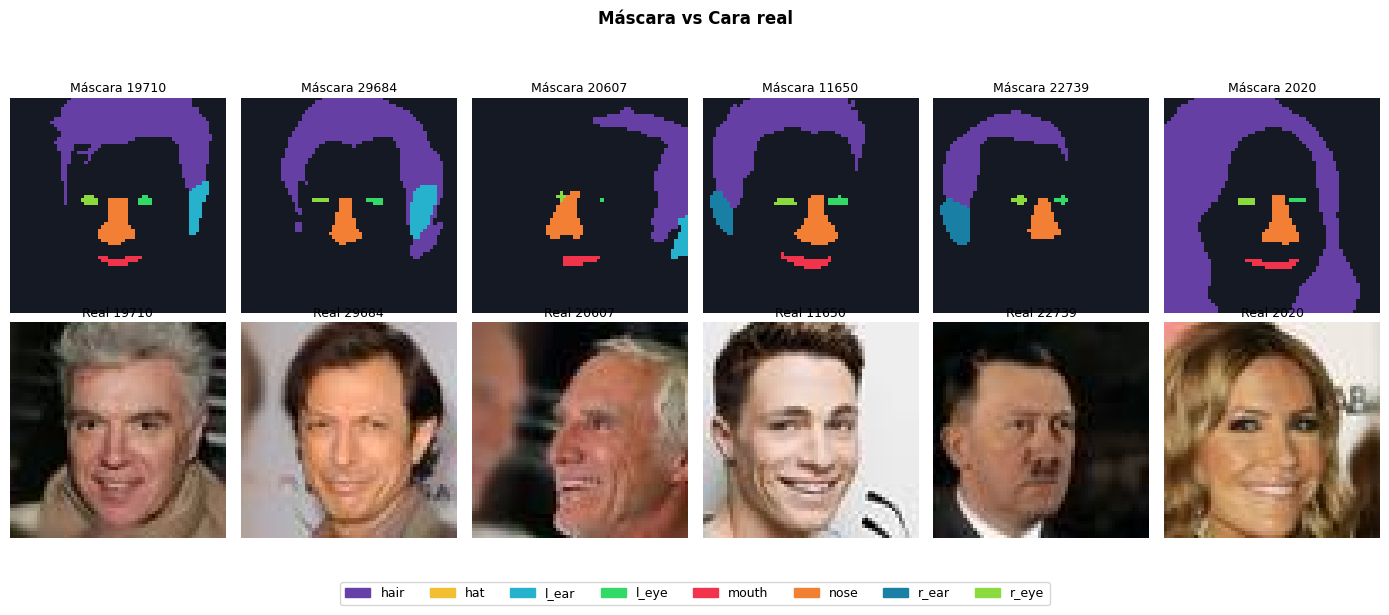

In [14]:
eda_indices = np.random.default_rng(SEED).choice(len(x_val), size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(14, 6.2))
for col_idx, val_idx in enumerate(eda_indices):
    axes[0, col_idx].imshow(colorize_mask(x_val[val_idx]))
    axes[0, col_idx].set_title(f"Máscara {ids_val[val_idx]}", fontsize=9, pad=4)
    axes[0, col_idx].axis("off")

    axes[1, col_idx].imshow(denormalize_image(y_val[val_idx]))
    axes[1, col_idx].set_title(f"Real {ids_val[val_idx]}", fontsize=9, pad=4)
    axes[1, col_idx].axis("off")

legend_handles = [
    mpatches.Patch(color=get_class_color(cls_name, idx), label=cls_name)
    for idx, cls_name in enumerate(MASK_CLASSES)
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=NUM_CLASSES,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.01),
)
plt.suptitle("Máscara vs Cara real", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0.08, 1, 0.94], h_pad=1.8)
plt.show()

In [15]:
# Cálculo del FID y cacheado previo para no entrenar el InceptionV3 en cada evaluación durante el entrenamiento del modelo
# de difusión. Se extraen las características de las 500 caras reales de validación y se guardan en memoria para compararlas
# con las caras generadas.

inception_extractor = NoTrainInceptionV3(
    name="inception-v3-compat", features_list=["2048"]
).to(INCEPTION_DEVICE).eval()


def extract_inception_features(images_01: np.ndarray, batch_size: int = FID_BATCH_SIZE) -> torch.Tensor:
    imgs_u8 = np.clip(images_01 * 255.0, 0.0, 255.0).round().astype(np.uint8)
    imgs_nchw = torch.from_numpy(np.ascontiguousarray(np.transpose(imgs_u8, (0, 3, 1, 2))))
    feats = []
    with torch.inference_mode():
        for start in range(0, len(imgs_nchw), batch_size):
            batch = imgs_nchw[start:start + batch_size].to(INCEPTION_DEVICE)
            feats.append(inception_extractor(batch).cpu().double())
    return torch.cat(feats, dim=0)


def compute_fid_from_features(real_feats: torch.Tensor, fake_feats: torch.Tensor) -> float:
    mu_r, mu_f = real_feats.mean(dim=0), fake_feats.mean(dim=0)
    dr, df = real_feats - mu_r, fake_feats - mu_f
    cov_r = (dr.T @ dr) / (len(real_feats) - 1)
    cov_f = (df.T @ df) / (len(fake_feats) - 1)
    return float(_compute_fid(mu_r, cov_r, mu_f, cov_f).item())

y_val_fid_01 = denormalize_image(y_val[:VAL_FID_SAMPLES])
real_val_fid_feats = extract_inception_features(y_val_fid_01)
print(f"Características reales de validación cacheadas: {tuple(real_val_fid_feats.shape)}")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 57.6MB/s]


Características reales de validación cacheadas: (500, 2048)


---

## **3. Arquitectura DiT condicional**

Construimos un DiT que recibe `[noisy_image (64x64x3), mask_input (64x64x8), timestep_input (entero)]` y predice el ruido ${\epsilon}$ de tamaño `(64x64x3)`:

- **Entrada condicionada:** concatenación `[noisy_image, mask]` de `64x64x11` (la máscara no se ensucia con ruido).
- ***Patchify*:** `Conv2D(kernel=4, strides=4)` sobre los 11 canales, que produce una rejilla `16x16` de **256 tokens** de dimensión `HIDDEN_DIM = 256`.
- **Embedding posicional 2D sin-cos fijo (no entrenable)** sumado a los tokens.
- **Paso temporal:** `SinusoidalTimeEmbedding` (la misma capa de la U-Net) seguido de un MLP (`Dense(256) -> SiLU -> Dense(256)`). Este vector $c$ solo alimenta a las capas adaLN.
- **`DEPTH = 8` bloques `DiTBlock`** con `NUM_HEADS = 4` y `MLP_RATIO = 4`: `LayerNorm` sin parámetros afines $\rightarrow$ modulación (*shift*, *scale*) $\rightarrow$ `MultiHeadAttention` $\rightarrow$ *gate* $\rightarrow$ residual; y después `LayerNorm` $\rightarrow$ modulación $\rightarrow$ MLP (`GELU`) $\rightarrow$ *gate* $\rightarrow$ residual. Una única `Dense` inicializada a **ceros** produce los 6 vectores de modulación (**adaLN-Zero**).
- **Capa final:** `LayerNorm` + modulación (*shift*, *scale*) + `Dense(4*4*3)` inicializada a ceros + *unpatchify* a `64x64x3`.

> Las capas auxiliares (embedding sin-cos, bloque adaLN-Zero, capa final) están adaptadas del repositorio oficial del DiT (`facebookresearch/DiT`, fichero `models.py`) y reescritas en Keras 3.

In [16]:
PKG = "dit_generator"


def get_1d_sincos_pos_embed(dim: int, positions: np.ndarray) -> np.ndarray:
    """Embedding sin-cos 1D: (len(positions), dim) con la mitad de senos y la mitad de cosenos."""
    omega = 1.0 / (10000.0 ** (np.arange(dim // 2, dtype=np.float64) / (dim // 2)))
    args = positions.reshape(-1, 1).astype(np.float64) * omega.reshape(1, -1)
    return np.concatenate([np.sin(args), np.cos(args)], axis=1)


def get_2d_sincos_pos_embed(dim: int, grid_size: int) -> np.ndarray:
    """Embedding posicional 2D fijo: la primera mitad codifica la fila y la segunda la columna del parche."""
    if dim % 4 != 0:
        raise ValueError("dim debe ser múltiplo de 4 para el embedding sin-cos 2D.")
    rows, cols = np.meshgrid(np.arange(grid_size), np.arange(grid_size), indexing="ij")
    emb_row = get_1d_sincos_pos_embed(dim // 2, rows.reshape(-1))
    emb_col = get_1d_sincos_pos_embed(dim // 2, cols.reshape(-1))
    return np.concatenate([emb_row, emb_col], axis=1).astype(np.float32)  # (grid_size^2, dim)


@keras.saving.register_keras_serializable(package=PKG)
class FixedPositionEmbedding2D(layers.Layer):
    """Suma a los tokens un embedding posicional sin-cos 2D FIJO (es una constante, no tiene pesos entrenables)."""

    def __init__(self, grid_size: int, dim: int, **kwargs):
        super().__init__(**kwargs)
        self.grid_size = int(grid_size)
        self.dim = int(dim)
        self.pos_embed = get_2d_sincos_pos_embed(self.dim, self.grid_size)[None, ...]  # (1, N, dim)

    def call(self, x):
        pos = keras.ops.convert_to_tensor(self.pos_embed, dtype=keras.backend.standardize_dtype(x.dtype))
        return x + pos

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        config = super().get_config()
        config.update({"grid_size": self.grid_size, "dim": self.dim})
        return config


@keras.saving.register_keras_serializable(package=PKG)
class SplitModulation(layers.Layer):
    """Divide el vector de modulación (batch, k*D) en k vectores (batch, D): shift, scale, gate..."""

    def __init__(self, num_chunks: int, **kwargs):
        super().__init__(**kwargs)
        self.num_chunks = int(num_chunks)

    def call(self, x):
        return tuple(keras.ops.split(x, self.num_chunks, axis=-1))

    def compute_output_shape(self, input_shape):
        d = input_shape[-1] // self.num_chunks
        return tuple((input_shape[0], d) for _ in range(self.num_chunks))

    def get_config(self):
        config = super().get_config()
        config.update({"num_chunks": self.num_chunks})
        return config


@keras.saving.register_keras_serializable(package=PKG)
class AdaLNModulate(layers.Layer):
    """Modulación adaLN: x * (1 + scale) + shift. scale y shift (batch, D) se difunden a todos los tokens."""

    def call(self, inputs):
        x, shift, scale = inputs
        return x * (1.0 + keras.ops.expand_dims(scale, 1)) + keras.ops.expand_dims(shift, 1)

    def compute_output_shape(self, input_shape):
        return input_shape[0]


@keras.saving.register_keras_serializable(package=PKG)
class GatedResidual(layers.Layer):
    """Residual con gate: x + gate * h. Con gate = 0 (inicio, adaLN-Zero) el bloque es la identidad."""

    def call(self, inputs):
        x, h, gate = inputs
        return x + keras.ops.expand_dims(gate, 1) * h

    def compute_output_shape(self, input_shape):
        return input_shape[0]


@keras.saving.register_keras_serializable(package=PKG)
class Unpatchify(layers.Layer):
    """Convierte los tokens (batch, N, P*P*C) de nuevo en una imagen (batch, H, W, C)."""

    def __init__(self, grid_size: int, patch_size: int, out_channels: int, **kwargs):
        super().__init__(**kwargs)
        self.grid_size = int(grid_size)
        self.patch_size = int(patch_size)
        self.out_channels = int(out_channels)

    def call(self, x):
        g, p, c = self.grid_size, self.patch_size, self.out_channels
        x = keras.ops.reshape(x, (-1, g, g, p, p, c))        # (batch, fila, col, py, px, c)
        x = keras.ops.transpose(x, (0, 1, 3, 2, 4, 5))       # (batch, fila, py, col, px, c)
        return keras.ops.reshape(x, (-1, g * p, g * p, c))   # (batch, H, W, c)

    def compute_output_shape(self, input_shape):
        side = self.grid_size * self.patch_size
        return (input_shape[0], side, side, self.out_channels)

    def get_config(self):
        config = super().get_config()
        config.update({"grid_size": self.grid_size, "patch_size": self.patch_size, "out_channels": self.out_channels})
        return config


@keras.saving.register_keras_serializable(package=PKG)
class SinusoidalTimeEmbedding(layers.Layer):
    """Embedding temporal basado en positional encoding para el paso t."""

    def __init__(self, dim: int = 64, max_period: float = 10000.0, **kwargs):
        super().__init__(**kwargs)
        if dim % 2 != 0:
            raise ValueError("dim debe ser par para el embedding.")
        self.dim = int(dim)
        self.max_period = float(max_period)

    def call(self, timesteps):
        half_dim = self.dim // 2
        t = keras.ops.cast(keras.ops.reshape(timesteps, (-1, 1)), "float32")
        freqs = keras.ops.exp(
            -math.log(self.max_period)
            * keras.ops.arange(half_dim, dtype="float32")
            / max(half_dim - 1, 1)
        )
        args = t * keras.ops.reshape(freqs, (1, half_dim))
        return keras.ops.concatenate([keras.ops.sin(args), keras.ops.cos(args)], axis=-1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], self.dim)

    def get_config(self):
        config = super().get_config()
        config.update({"dim": self.dim, "max_period": self.max_period})
        return config

In [17]:
def dit_block(x, c, hidden_dim: int, num_heads: int, mlp_ratio: int, name_prefix: str = "dit_block"):
    """Bloque DiT con adaLN-Zero.
    x: tokens (batch, N, D) | c: embedding del paso t (batch, D)."""
    # Una única Dense produce los 6 vectores de modulación. Se inicializa a CEROS (adaLN-Zero):
    # así los gates valen 0 y el bloque empieza siendo la identidad.
    c_act = layers.Activation("silu", name=f"{name_prefix}_c_silu")(c)
    mod = layers.Dense(
        6 * hidden_dim,
        kernel_initializer="zeros",
        bias_initializer="zeros",
        name=f"{name_prefix}_adaln",
    )(c_act)
    shift1, scale1, gate1, shift2, scale2, gate2 = SplitModulation(6, name=f"{name_prefix}_split")(mod)

    # 1) Atención: LayerNorm (sin parámetros afines) -> modulación -> MHSA -> gate -> residual
    h = layers.LayerNormalization(epsilon=1e-6, center=False, scale=False, name=f"{name_prefix}_ln1")(x)
    h = AdaLNModulate(name=f"{name_prefix}_mod1")([h, shift1, scale1])
    h = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=hidden_dim // num_heads,
        name=f"{name_prefix}_mha",
    )(h, h)
    x = GatedResidual(name=f"{name_prefix}_res1")([x, h, gate1])

    # 2) MLP: LayerNorm (sin parámetros afines) -> modulación -> MLP (GELU) -> gate -> residual
    h = layers.LayerNormalization(epsilon=1e-6, center=False, scale=False, name=f"{name_prefix}_ln2")(x)
    h = AdaLNModulate(name=f"{name_prefix}_mod2")([h, shift2, scale2])
    h = layers.Dense(hidden_dim * mlp_ratio, activation="gelu", name=f"{name_prefix}_mlp_1")(h)
    h = layers.Dense(hidden_dim, name=f"{name_prefix}_mlp_2")(h)
    return GatedResidual(name=f"{name_prefix}_out")([x, h, gate2])


def build_dit(
    num_classes: int = NUM_CLASSES,
    patch_size: int = PATCH_SIZE,
    hidden_dim: int = HIDDEN_DIM,
    depth: int = DEPTH,
    num_heads: int = NUM_HEADS,
    mlp_ratio: int = MLP_RATIO,
    time_dim: int = TIME_DIM,
    name: str = "conditional_dit",
) -> keras.Model:
    grid = IMG_SIZE // patch_size

    noisy_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="noisy_image")
    mask_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, num_classes), name="mask_input")
    timestep_input = keras.Input(shape=(), dtype="int32", name="timestep_input")

    # Embedding temporal sinusoidal + MLP (Dense(256) -> SiLU -> Dense(256)): es el vector c de adaLN
    c = SinusoidalTimeEmbedding(dim=time_dim, name="time_sinusoidal")(timestep_input)
    c = layers.Dense(time_dim, activation="silu", name="time_mlp_1")(c)
    c = layers.Dense(time_dim, name="time_mlp_2")(c)

    # Concatenación [noisy_image, mask] -> (64, 64, 11). La máscara nunca se ensucia con ruido.
    x = layers.Concatenate(axis=-1, name="cond_concat")([noisy_input, mask_input])

    # Patchify: Conv2D(4x4, strides=4) -> (16, 16, D) -> 256 tokens de dimensión D
    x = layers.Conv2D(hidden_dim, kernel_size=patch_size, strides=patch_size, name="patch_embed")(x)
    x = layers.Reshape((grid * grid, hidden_dim), name="to_tokens")(x)

    # Embedding posicional 2D sin-cos FIJO (no entrenable)
    x = FixedPositionEmbedding2D(grid, hidden_dim, name="pos_embed")(x)

    # Pila de bloques DiT
    for i in range(depth):
        x = dit_block(x, c, hidden_dim, num_heads, mlp_ratio, name_prefix=f"dit_block_{i}")

    # Capa final: LayerNorm + modulación (shift, scale) + Dense a P*P*3 (init a ceros) + unpatchify
    c_act = layers.Activation("silu", name="final_c_silu")(c)
    final_mod = layers.Dense(
        2 * hidden_dim,
        kernel_initializer="zeros",
        bias_initializer="zeros",
        name="final_adaln",
    )(c_act)
    final_shift, final_scale = SplitModulation(2, name="final_split")(final_mod)
    x = layers.LayerNormalization(epsilon=1e-6, center=False, scale=False, name="final_ln")(x)
    x = AdaLNModulate(name="final_mod")([x, final_shift, final_scale])
    x = layers.Dense(
        patch_size * patch_size * CHANNELS,
        kernel_initializer="zeros",
        bias_initializer="zeros",
        dtype="float32",  # la salida siempre en float32 (importante con mixed_float16)
        name="final_proj",
    )(x)
    pred_noise = Unpatchify(grid, patch_size, CHANNELS, name="pred_noise")(x)

    return keras.Model(
        inputs=[noisy_input, mask_input, timestep_input],
        outputs=pred_noise,
        name=name,
    )

In [18]:
dit = build_dit(NUM_CLASSES, name="dit")
dit.summary()

DIT_N_PARAMS = int(dit.count_params())
UNET_N_PARAMS = 9_423_107  # parámetros de la U-Net de diffusion_generator (summary() de ese notebook)
print(f"\nParámetros del DiT: {DIT_N_PARAMS:,} ({DIT_N_PARAMS / 1e6:.2f} M) | U-Net: {UNET_N_PARAMS:,} ({UNET_N_PARAMS / 1e6:.2f} M)")
print(f"Rango objetivo 9-10 M: {'OK' if 9e6 <= DIT_N_PARAMS <= 10e6 else 'FUERA DE RANGO'}")

# Comprobaciones de forma de cada etapa
_GRID = IMG_SIZE // PATCH_SIZE
assert dit.get_layer("cond_concat").output.shape[1:] == (IMG_SIZE, IMG_SIZE, CHANNELS + NUM_CLASSES)
assert dit.get_layer("to_tokens").output.shape[1:] == (_GRID * _GRID, HIDDEN_DIM)
assert dit.get_layer("pred_noise").output.shape[1:] == (IMG_SIZE, IMG_SIZE, CHANNELS)

# Comprobación de adaLN-Zero: al inicio el modelo predice exactamente ruido cero
_probe = dit.predict(
    [np.zeros((2, IMG_SIZE, IMG_SIZE, CHANNELS), np.float32), x_val[:2], np.array([10, 500], np.int32)],
    verbose=0,
)
print(f"Salida inicial |eps_pred| máx = {np.abs(_probe).max():.1e} (debe ser 0 por la inicialización a ceros)")

Model: "dit"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ timestep_input      │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noisy_image         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_input          │ (None, 64, 64, 8) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_sinusoidal     │ (None, 256)       │          0 │ timestep_input[0… │
│ (SinusoidalTimeEmb… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cond_concat         │ (None, 64, 64,    │          0 │ noisy_image[0][0… │
│ (Concatenate)       │ 11)               │            │ mask_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_mlp_1 (Dense)  │ (None, 256)       │     65,792 │ time_sinusoidal[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embed         │ (None, 16, 16,    │     45,312 │ cond_concat[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_mlp_2 (Dense)  │ (None, 256)       │     65,792 │ time_mlp_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_tokens (Reshape) │ (None, 256, 256)  │          0 │ patch_embed[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dit_block_0_c_silu  │ (None, 256)       │          0 │ time_mlp_2[0][0]  │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_embed           │ (None, 256, 256)  │          0 │ to_tokens[0][0]   │
│ (FixedPositionEmbe… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dit_block_0_adaln   │ (None, 1536)      │    394,752 │ dit_block_0_c_si… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dit_block_0_ln1     │ (None, 256, 256)  │          0 │ pos_embed[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dit_block_0_split   │ [(None, 256),     │          0 │ dit_block_0_adal… │
│ (SplitModulation)   │ (None, 256),      │            │                   │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dit_block_0_mod1    │ (None, 256, 256)  │          0 │ dit_block_0_ln1[… │
│ (AdaLNModulate)     │                   │            │ dit_block_0_spli… │
│                     │                   │            │ dit_block_0_spli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dit_block_0_mha     │ (None, 256, 256)  │    263,168 │ dit_block_0_mod1… │
│ (MultiHeadAttentio… │                   │            │ dit_block_0_mod1

 Total params: 9,788,720 (37.34 MB)

 Trainable params: 9,788,720 (37.34 MB)

 Non-trainable params: 0 (0.00 B)


Parámetros del DiT: 9,788,720 (9.79 M) | U-Net: 9,423,107 (9.42 M)
Rango objetivo 9-10 M: OK
Salida inicial |eps_pred| máx = 0.0e+00 (debe ser 0 por la inicialización a ceros)


### **3.1 Esquema de la arquitectura**

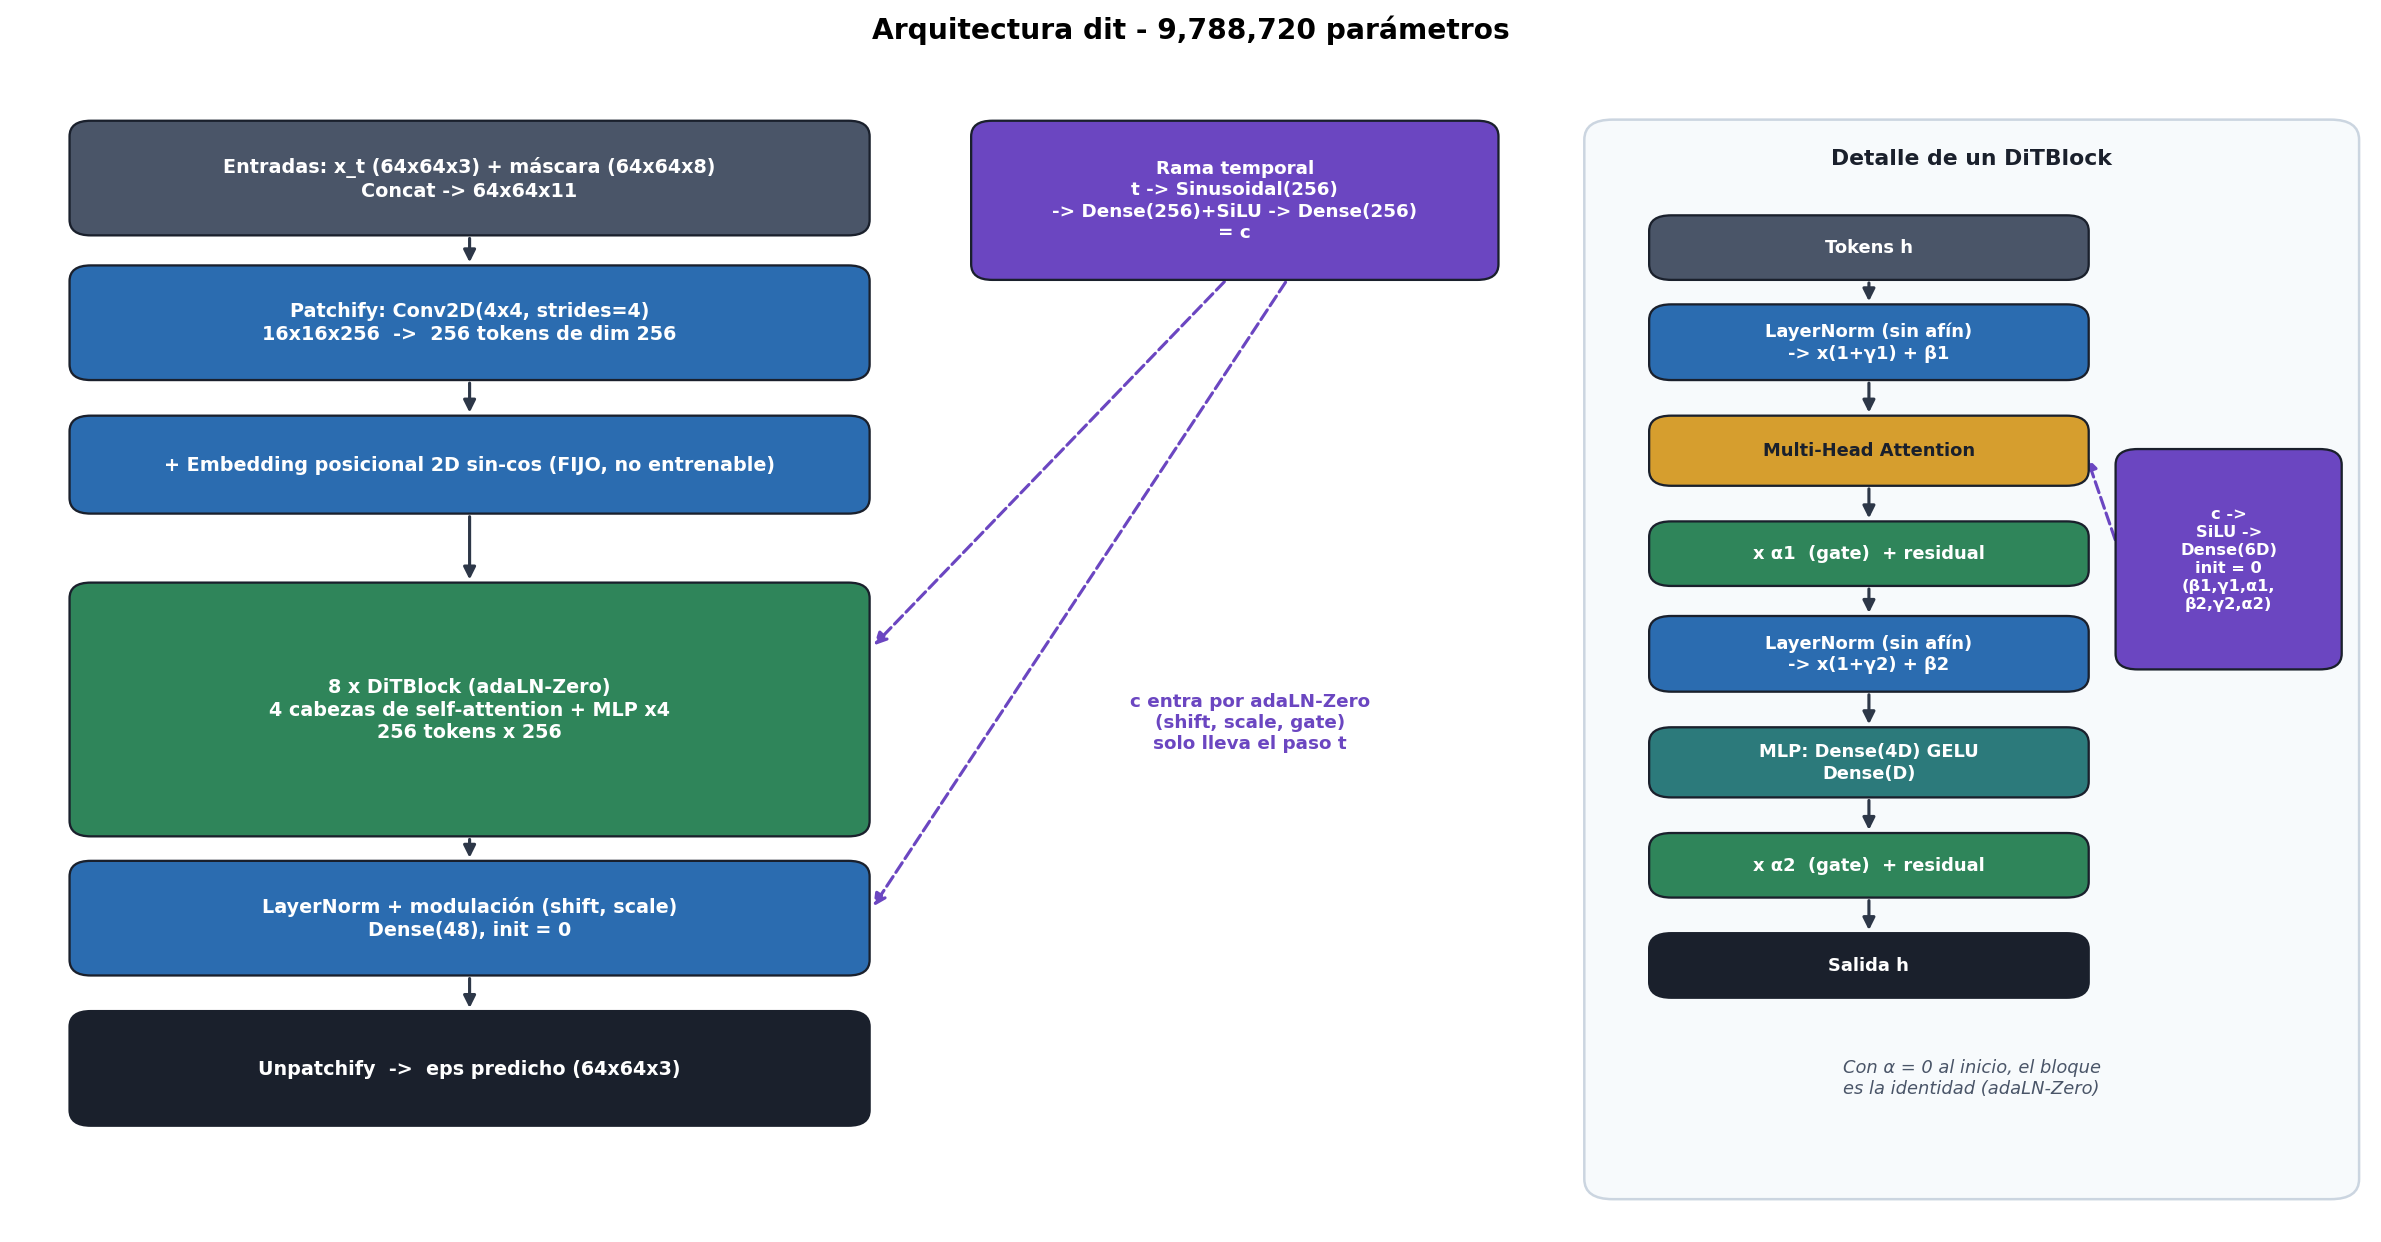

In [19]:
def plot_dit_architecture(model: keras.Model, save_path: Path | None = CHECKPOINT_DIR / "dit_architecture.png"):
    """Dibuja el esquema del DiT y el detalle de un bloque adaLN-Zero."""
    grid = IMG_SIZE // PATCH_SIZE
    n_tok = grid * grid

    def _shape(layer_name: str) -> tuple[int, ...]:
        return tuple(int(d) for d in model.get_layer(layer_name).output.shape[1:])

    assert _shape("cond_concat") == (IMG_SIZE, IMG_SIZE, CHANNELS + NUM_CLASSES)
    assert _shape("patch_embed") == (grid, grid, HIDDEN_DIM)
    assert _shape("pos_embed") == (n_tok, HIDDEN_DIM)
    assert _shape(f"dit_block_{DEPTH - 1}_out") == (n_tok, HIDDEN_DIM)
    assert _shape("final_proj") == (n_tok, PATCH_SIZE * PATCH_SIZE * CHANNELS)
    assert _shape("pred_noise") == (IMG_SIZE, IMG_SIZE, CHANNELS)

    C_IO, C_PATCH, C_BLOCK, C_ATTN, C_MLP, C_TIME, C_OUT = (
        "#4A5568", "#2B6CB0", "#2F855A", "#D69E2E", "#2C7A7B", "#6B46C1", "#1A202C",
    )

    def draw_box(axis, x, y, w, h, text, color, fontsize=9.0, textcolor="white"):
        axis.add_patch(mpatches.FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.14",
            facecolor=color, edgecolor="#1A202C", linewidth=1.1, zorder=3,
        ))
        axis.text(x + w / 2, y + h / 2, text, ha="center", va="center", color=textcolor,
                  fontsize=fontsize, fontweight="bold", zorder=4, linespacing=1.25)

    def draw_arrow(axis, p0, p1, color="#2D3748", lw=1.5, ls="-"):
        axis.add_patch(mpatches.FancyArrowPatch(
            p0, p1, arrowstyle="-|>", mutation_scale=12, color=color, linewidth=lw, linestyle=ls, zorder=2,
        ))

    fig = plt.figure(figsize=(16, 8.6), dpi=150)
    gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1.2], wspace=0.04)
    ax = fig.add_subplot(gs[0, 0])
    ax_r = fig.add_subplot(gs[0, 1])
    ax.set_xlim(0, 10); ax.set_ylim(0, 10.2); ax.axis("off")
    ax_r.set_xlim(0, 5); ax_r.set_ylim(0, 10.2); ax_r.axis("off")

    # Columna principal (flujo de tokens)
    x0, w = 0.4, 5.2
    xc = x0 + w / 2
    main = [
        (8.95, 0.95, f"Entradas: x_t ({IMG_SIZE}x{IMG_SIZE}x{CHANNELS}) + máscara ({IMG_SIZE}x{IMG_SIZE}x{NUM_CLASSES})\nConcat -> {IMG_SIZE}x{IMG_SIZE}x{CHANNELS + NUM_CLASSES}", C_IO),
        (7.65, 0.95, f"Patchify: Conv2D({PATCH_SIZE}x{PATCH_SIZE}, strides={PATCH_SIZE})\n{grid}x{grid}x{HIDDEN_DIM}  ->  {n_tok} tokens de dim {HIDDEN_DIM}", C_PATCH),
        (6.45, 0.80, "+ Embedding posicional 2D sin-cos (FIJO, no entrenable)", C_PATCH),
        (3.55, 2.20, f"{DEPTH} x DiTBlock (adaLN-Zero)\n{NUM_HEADS} cabezas de self-attention + MLP x{MLP_RATIO}\n{n_tok} tokens x {HIDDEN_DIM}", C_BLOCK),
        (2.30, 0.95, f"LayerNorm + modulación (shift, scale)\nDense({PATCH_SIZE * PATCH_SIZE * CHANNELS}), init = 0", C_PATCH),
        (0.95, 0.95, f"Unpatchify  ->  eps predicho ({IMG_SIZE}x{IMG_SIZE}x{CHANNELS})", C_OUT),
    ]
    for y, h, text, color in main:
        draw_box(ax, x0, y, w, h, text, color, fontsize=9.2)
    for (y_a, _, _, _), (y_b, h_b, _, _) in zip(main[:-1], main[1:]):
        draw_arrow(ax, (xc, y_a - 0.03), (xc, y_b + h_b + 0.03))

    # Rama temporal -> adaLN de cada bloque y de la capa final
    draw_box(ax, 6.35, 8.55, 3.4, 1.35, "Rama temporal\nt -> Sinusoidal(256)\n-> Dense(256)+SiLU -> Dense(256)\n= c", C_TIME, fontsize=8.8)
    draw_arrow(ax, (8.0, 8.52), (5.65, 5.2), color=C_TIME, ls="--")
    draw_arrow(ax, (8.4, 8.52), (5.65, 2.85), color=C_TIME, ls="--")
    ax.text(8.15, 4.3, "c entra por adaLN-Zero\n(shift, scale, gate)\nsolo lleva el paso t", ha="center", fontsize=8.8,
            fontweight="bold", color=C_TIME)

    # Panel derecho: detalle de un DiTBlock
    ax_r.add_patch(mpatches.FancyBboxPatch(
        (0.1, 0.3), 4.8, 9.6, boxstyle="round,pad=0.05,rounding_size=0.18",
        facecolor="#F7FAFC", edgecolor="#CBD5E0", linewidth=1.2, zorder=1,
    ))
    ax_r.text(2.5, 9.55, "Detalle de un DiTBlock", ha="center", fontsize=10.5, fontweight="bold", color="#1A202C")
    rx, rw = 0.5, 2.7
    detail = [
        (8.55, 0.50, "Tokens h", C_IO),
        (7.65, 0.60, "LayerNorm (sin afín)\n-> x(1+γ1) + β1", C_PATCH),
        (6.70, 0.55, "Multi-Head Attention", C_ATTN),
        (5.80, 0.50, "x α1  (gate)  + residual", C_BLOCK),
        (4.85, 0.60, "LayerNorm (sin afín)\n-> x(1+γ2) + β2", C_PATCH),
        (3.90, 0.55, f"MLP: Dense({MLP_RATIO}D) GELU\nDense(D)", C_MLP),
        (3.00, 0.50, "x α2  (gate)  + residual", C_BLOCK),
        (2.10, 0.50, "Salida h", C_OUT),
    ]
    for y, h, text, color in detail:
        draw_box(ax_r, rx, y, rw, h, text, color, fontsize=8.6, textcolor="#1A202C" if color == C_ATTN else "white")
    for (y_a, _, _, _), (y_b, h_b, _, _) in zip(detail[:-1], detail[1:]):
        draw_arrow(ax_r, (rx + rw / 2, y_a - 0.03), (rx + rw / 2, y_b + h_b + 0.03))
    draw_box(ax_r, 3.45, 5.05, 1.35, 1.9, "c ->\nSiLU ->\nDense(6D)\ninit = 0\n(β1,γ1,α1,\nβ2,γ2,α2)", C_TIME, fontsize=7.8)
    draw_arrow(ax_r, (3.45, 6.0), (3.22, 6.95), color=C_TIME, ls="--")
    ax_r.text(2.5, 1.2, "Con α = 0 al inicio, el bloque\nes la identidad (adaLN-Zero)", ha="center",
              fontsize=8.6, style="italic", color="#4A5568")

    fig.suptitle(f"Arquitectura {model.name} - {model.count_params():,} parámetros", fontsize=13.5, fontweight="bold", y=0.97)
    fig.subplots_adjust(left=0.01, right=0.99, top=0.91, bottom=0.03)
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_dit_architecture(dit)

---

## **4. *Cosine schedule*, aumentación, `ConditionalDDPM` con EMA y callback de FID**

- ***Cosine schedule***: idéntico al de la U-Net. Gracias a la propiedad reproductiva de las gaussianas, saltamos directamente a cualquier $t \in \{0, \dots, T-1\}$ en tiempo $\mathcal{O}(1)$:
   $$x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1-\bar{\alpha}_t}\,\epsilon, \qquad \bar{\alpha}_t = \frac{f(t)}{f(0)}, \quad f(t) = \cos^2\!\left(\frac{t/T + s}{1+s}\cdot\frac{\pi}{2}\right), \quad s = 0.008$$

- **Aumentación conjunta máscara + cara (`_prepare_train_sample`):** flip horizontal aleatorio con intercambio de canales simétricos (`l_eye <-> r_eye` y `l_ear <-> r_ear`) y, con probabilidad `0.35`, ampliación (`+2` a `+4` píxeles) con recorte aleatorio a `64x64` (`nearest` para la máscara y `bilinear` para la cara).

- **`ConditionalDDPM`:** igual que en la U-Net (un $t$ uniforme por muestra, ruido gaussiano y MSE entre ruido real y predicho) y con una **copia EMA** de los pesos que se actualiza tras cada paso de entrenamiento:
   $$\theta_{\text{EMA}} \leftarrow d\,\theta_{\text{EMA}} + (1-d)\,\theta, \qquad d = 0.999$$

- **`ddim_sample`:** el mismo muestreador DDIM, con un argumento `use_ema` para elegir entre pesos normales y EMA.

- **Callback `ValFIDAndTrackerCallback`:** cada `VAL_FID_EVERY = 5` épocas (y en la última) genera las `500` caras de validación con **DDIM (`25` pasos, $\eta = 0$)** usando los pesos normales **y** los EMA, y guarda ambos FID en el historial. Guarda en Drive el mejor checkpoint según el menor de los dos FID.

Cosine schedule listo (T=1000): alpha_bar[0]=0.99996 | alpha_bar[500]=0.4923 | alpha_bar[999]=2.64e-05


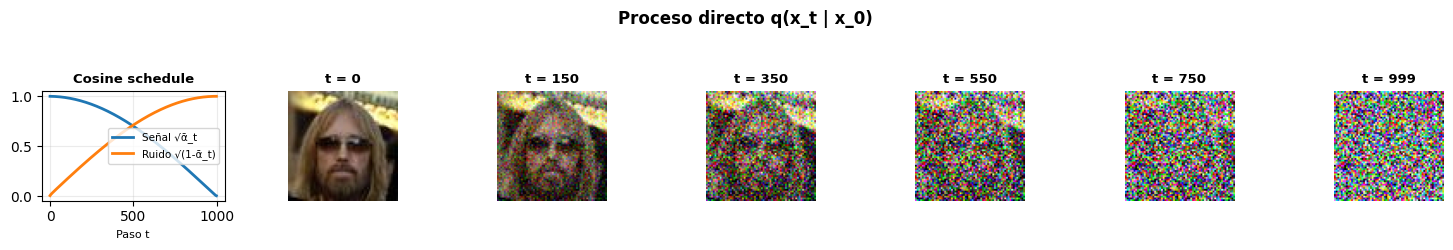

In [20]:
class CosineDiffusionSchedule:
    """Cosine schedule para T pasos."""

    def __init__(self, timesteps: int = TIMESTEPS, s: float = COSINE_S, beta_max: float = 0.2):
        self.timesteps = int(timesteps)
        self.s = float(s)

        steps = np.linspace(0, self.timesteps, self.timesteps + 1, dtype=np.float64)
        f_t = np.cos(((steps / self.timesteps) + self.s) / (1.0 + self.s) * (np.pi / 2.0)) ** 2
        alphas_cumprod_ext = f_t / f_t[0]

        betas = np.clip(1.0 - (alphas_cumprod_ext[1:] / alphas_cumprod_ext[:-1]), 1e-5, beta_max)
        alphas = 1.0 - betas
        alphas_cumprod = np.cumprod(alphas, axis=0)

        self.betas_np = betas.astype(np.float32)
        self.alphas_np = alphas.astype(np.float32)
        self.alphas_cumprod_np = alphas_cumprod.astype(np.float32)
        self.sqrt_alphas_cumprod_np = np.sqrt(alphas_cumprod).astype(np.float32)
        self.sqrt_one_minus_alphas_cumprod_np = np.sqrt(1.0 - alphas_cumprod).astype(np.float32)

        self.sqrt_alphas_cumprod = tf.constant(self.sqrt_alphas_cumprod_np, dtype=tf.float32)
        self.sqrt_one_minus_alphas_cumprod = tf.constant(
            self.sqrt_one_minus_alphas_cumprod_np, dtype=tf.float32
        )

    def q_sample(self, x0: tf.Tensor, t: tf.Tensor, noise: tf.Tensor) -> tf.Tensor:
        """Muestrea q(x_t | x_0) en forma cerrada."""
        a_bar = tf.reshape(tf.gather(self.sqrt_alphas_cumprod, t), (-1, 1, 1, 1))
        one_m_a_bar = tf.reshape(tf.gather(self.sqrt_one_minus_alphas_cumprod, t), (-1, 1, 1, 1))
        return a_bar * x0 + one_m_a_bar * noise


diffusion_schedule = CosineDiffusionSchedule(timesteps=TIMESTEPS, s=COSINE_S)
print(
    f"Cosine schedule listo (T={diffusion_schedule.timesteps}): "
    f"alpha_bar[0]={diffusion_schedule.alphas_cumprod_np[0]:.5f} | "
    f"alpha_bar[500]={diffusion_schedule.alphas_cumprod_np[500]:.4f} | "
    f"alpha_bar[999]={diffusion_schedule.alphas_cumprod_np[-1]:.2e}"
)

# Visualización rápida del proceso directo q(x_t | x_0) sobre una cara de validación
demo_steps = [0, 150, 350, 550, 750, 999]
demo_x0 = tf.convert_to_tensor(y_val[0:1], dtype=tf.float32)
demo_eps = tf.convert_to_tensor(
    np.random.default_rng(SEED).standard_normal(demo_x0.shape).astype(np.float32)
)

fig, axes = plt.subplots(1, len(demo_steps) + 1, figsize=(15, 2.5))
t_axis = np.arange(TIMESTEPS)
axes[0].plot(t_axis, diffusion_schedule.sqrt_alphas_cumprod_np, label="Señal √ᾱ_t", linewidth=2)
axes[0].plot(t_axis, diffusion_schedule.sqrt_one_minus_alphas_cumprod_np, label="Ruido √(1-ᾱ_t)", linewidth=2)
axes[0].set_title("Cosine schedule", fontsize=9.5, fontweight="bold")
axes[0].set_xlabel("Paso t", fontsize=8)
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=7.5, loc="center right")

for idx, t_val in enumerate(demo_steps):
    x_noisy = diffusion_schedule.q_sample(demo_x0, tf.constant([t_val], dtype=tf.int32), demo_eps).numpy()[0]
    axes[idx + 1].imshow(denormalize_image(x_noisy))
    axes[idx + 1].set_title(f"t = {t_val}", fontsize=9.5, fontweight="bold")
    axes[idx + 1].axis("off")

plt.suptitle("Proceso directo q(x_t | x_0)", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [21]:
_FLIP_PERM = list(range(NUM_CLASSES))
for _left_cls, _right_cls in (("l_ear", "r_ear"), ("l_eye", "r_eye")):
    if _left_cls in MASK_CLASSES and _right_cls in MASK_CLASSES:
        _li, _ri = MASK_CLASSES.index(_left_cls), MASK_CLASSES.index(_right_cls)
        _FLIP_PERM[_li], _FLIP_PERM[_ri] = _ri, _li
FLIP_PERM_TENSOR = tf.constant(_FLIP_PERM, dtype=tf.int32)


def _prepare_train_sample(mask_u8, img_u8):
    mask_f = tf.cast(mask_u8, tf.float32)
    img_f = (tf.cast(img_u8, tf.float32) / 127.5) - 1.0

    do_flip = tf.random.uniform(()) > 0.5
    mask_f = tf.cond(
        do_flip,
        lambda: tf.gather(tf.image.flip_left_right(mask_f), FLIP_PERM_TENSOR, axis=-1),
        lambda: mask_f,
    )
    img_f = tf.cond(do_flip, lambda: tf.image.flip_left_right(img_f), lambda: img_f)

    do_affine = tf.random.uniform(()) < 0.35

    def _zoom_and_crop():
        new_sz = tf.random.uniform((), minval=IMG_SIZE + 2, maxval=IMG_SIZE + 5, dtype=tf.int32)
        m_big = tf.image.resize(mask_f, (new_sz, new_sz), method="nearest")
        i_big = tf.image.resize(img_f, (new_sz, new_sz), method="bilinear")
        max_off = new_sz - IMG_SIZE + 1
        oy = tf.random.uniform((), minval=0, maxval=max_off, dtype=tf.int32)
        ox = tf.random.uniform((), minval=0, maxval=max_off, dtype=tf.int32)
        m_crop = tf.image.crop_to_bounding_box(m_big, oy, ox, IMG_SIZE, IMG_SIZE)
        i_crop = tf.image.crop_to_bounding_box(i_big, oy, ox, IMG_SIZE, IMG_SIZE)
        m_crop.set_shape((IMG_SIZE, IMG_SIZE, NUM_CLASSES))
        i_crop.set_shape((IMG_SIZE, IMG_SIZE, CHANNELS))
        return m_crop, i_crop

    return tf.cond(do_affine, _zoom_and_crop, lambda: (mask_f, img_f))

In [22]:
class ConditionalDDPM(keras.Model):
    """Entrenamiento DDPM condicional con predicción de ruido (MSE) y pesos EMA."""

    def __init__(
        self,
        dit_model: keras.Model,
        ema_model: keras.Model,
        schedule: CosineDiffusionSchedule = diffusion_schedule,
        ema_decay: float = EMA_DECAY,
    ):
        super().__init__()
        self.dit = dit_model
        self.ema_model = ema_model
        self.ema_model.trainable = False  # la copia EMA no se entrena con gradientes, solo se promedia
        self.schedule = schedule
        self.ema_decay = float(ema_decay)
        self.loss_tracker = keras.metrics.Mean(name="loss")
        if len(self.ema_model.weights) != len(self.dit.weights):
            raise ValueError("El modelo EMA debe tener exactamente la misma arquitectura que el DiT.")

    @property
    def metrics(self):
        return [self.loss_tracker]

    def call(self, inputs, training: bool = False):
        return self.dit(inputs, training=training)

    def _update_ema(self):
        # theta_EMA <- d * theta_EMA + (1 - d) * theta, tras cada paso del optimizador
        d = self.ema_decay
        for ema_w, w in zip(self.ema_model.weights, self.dit.weights):
            ema_w.assign(d * ema_w + (1.0 - d) * w)

    def train_step(self, data):
        masks, images = data
        batch_size = tf.shape(images)[0]
        t = tf.random.uniform((batch_size,), minval=0, maxval=self.schedule.timesteps, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(images), dtype=tf.float32)
        noisy_images = self.schedule.q_sample(images, t, noise)

        with tf.GradientTape() as tape:
            pred_noise = tf.cast(self.dit([noisy_images, masks, t], training=True), tf.float32)
            loss = tf.reduce_mean(tf.square(noise - pred_noise))
            # Con mixed_float16 la pérdida se escala para evitar underflow; con float32 no hace nada
            scaled_loss = self.optimizer.scale_loss(loss)

        grads = tape.gradient(scaled_loss, self.dit.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.dit.trainable_variables))
        self._update_ema()

        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    def test_step(self, data):
        masks, images = data
        batch_size = tf.shape(images)[0]
        t = tf.random.uniform((batch_size,), minval=0, maxval=self.schedule.timesteps, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(images), dtype=tf.float32)
        noisy_images = self.schedule.q_sample(images, t, noise)

        pred_noise = tf.cast(self.dit([noisy_images, masks, t], training=False), tf.float32)
        loss = tf.reduce_mean(tf.square(noise - pred_noise))

        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

In [23]:
_DDIM_PREDICT_CACHE = {}

def _get_ddim_predict_fn(model: keras.Model):
    model_id = id(model)
    cached = _DDIM_PREDICT_CACHE.get(model_id)
    if cached is None or cached[0] is not model:
        @tf.function(
            input_signature=[
                tf.TensorSpec(shape=(None, IMG_SIZE, IMG_SIZE, CHANNELS), dtype=tf.float32),
                tf.TensorSpec(shape=(None, IMG_SIZE, IMG_SIZE, NUM_CLASSES), dtype=tf.float32),
                tf.TensorSpec(shape=(None,), dtype=tf.int32),
            ]
        )
        def _predict_eps(x_in, m_in, t_in):
            return model([x_in, m_in, t_in], training=False)

        _DDIM_PREDICT_CACHE[model_id] = (model, _predict_eps)
    return _DDIM_PREDICT_CACHE[model_id][1]


def ddim_sample(
    model: keras.Model,
    masks: np.ndarray,
    steps: int = EVAL_DDIM_STEPS,
    eta: float = EVAL_DDIM_ETA,
    seed: int | None = None,
    initial_noise: np.ndarray | None = None,
    batch_size: int = BATCH_SIZE,
    schedule=None,
    use_ema: bool = False,
    ema_model: keras.Model | None = None,
) -> np.ndarray:
    """Genera caras en [-1, 1] desde máscaras mediante muestreo DDIM (determinista si eta=0).
    use_ema=False usa los pesos normales (`model`); use_ema=True usa la copia EMA (`ema_model`)."""
    if use_ema:
        if ema_model is None:
            raise ValueError("use_ema=True requiere pasar ema_model.")
        model = ema_model
    sched = diffusion_schedule if schedule is None else schedule
    single_input = masks.ndim == 3
    masks_4d = masks[None, ...].astype(np.float32) if single_input else masks.astype(np.float32)
    n_samples = len(masks_4d)

    rng = np.random.default_rng(seed)
    if initial_noise is not None:
        noise_all = initial_noise.astype(np.float32)
        if noise_all.ndim == 3:
            noise_all = noise_all[None, ...]
    else:
        noise_all = rng.standard_normal((n_samples, IMG_SIZE, IMG_SIZE, CHANNELS)).astype(np.float32)

    timestep_seq = np.round(np.linspace(sched.timesteps - 1, 0, int(steps))).astype(np.int32)
    alphas_cumprod = sched.alphas_cumprod_np

    _predict_eps = _get_ddim_predict_fn(model)

    outputs = []
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        mask_b = tf.convert_to_tensor(masks_4d[start:end], dtype=tf.float32)
        x_t = tf.convert_to_tensor(noise_all[start:end], dtype=tf.float32)
        cur_bs = end - start

        for i, t_curr in enumerate(timestep_seq):
            t_b = tf.fill((cur_bs,), tf.cast(t_curr, tf.int32))
            eps_pred = _predict_eps(x_t, mask_b, t_b)

            alpha_bar_t = float(alphas_cumprod[int(t_curr)])
            sqrt_alpha_t = math.sqrt(alpha_bar_t)
            sqrt_one_minus_t = math.sqrt(max(0.0, 1.0 - alpha_bar_t))

            pred_x0 = (x_t - sqrt_one_minus_t * eps_pred) / sqrt_alpha_t
            pred_x0 = tf.clip_by_value(pred_x0, -1.0, 1.0)

            if i == len(timestep_seq) - 1:
                x_t = pred_x0
            else:
                alpha_bar_prev = float(alphas_cumprod[int(timestep_seq[i + 1])])
                sigma_t = float(eta) * math.sqrt(
                    max(0.0, (1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t))
                    * max(0.0, 1.0 - (alpha_bar_t / alpha_bar_prev))
                )
                dir_coeff = math.sqrt(max(0.0, 1.0 - alpha_bar_prev - sigma_t ** 2))
                x_t = math.sqrt(alpha_bar_prev) * pred_x0 + dir_coeff * eps_pred
                if sigma_t > 0.0:
                    z = tf.convert_to_tensor(
                        rng.standard_normal((cur_bs, IMG_SIZE, IMG_SIZE, CHANNELS)).astype(np.float32)
                    )
                    x_t = x_t + sigma_t * z

        outputs.append(np.clip(x_t.numpy(), -1.0, 1.0))

    result = np.concatenate(outputs, axis=0)
    return result[0] if single_input else result

In [24]:
def _atomic_save_model(model: keras.Model, path: Path):
    """Guarda en un fichero temporal y lo renombra: una desconexión a mitad no corrompe el checkpoint."""
    tmp_path = path.with_name(path.stem + "_tmp.keras")
    model.save(tmp_path)
    os.replace(tmp_path, path)


def new_history() -> dict:
    return {
        "loss": [],
        "val_loss": [],
        "epoch_time_s": [],          # tiempo de cada época sin contar el FID
        "val_fid_epochs": [],
        "val_fid_scores": [],        # FID de validación con pesos normales
        "val_fid_ema_scores": [],    # FID de validación con pesos EMA
        "best_val_fid": float("inf"),
        "best_val_fid_epoch": 0,
        "best_kind": "normal",       # "normal" o "ema": qué pesos dieron el mejor FID
        "val_ddim_steps": VAL_DDIM_STEPS,
        "n_params": None,
    }


class ValFIDAndTrackerCallback(keras.callbacks.Callback):
    """Evalúa val_fid cada VAL_FID_EVERY épocas con DDIM (pesos normales y EMA) y guarda el mejor checkpoint."""

    def __init__(
        self,
        eval_masks: np.ndarray,
        real_feats: torch.Tensor,
        history: dict,
        total_epochs: int = EPOCHS,
        every: int = VAL_FID_EVERY,
        ddim_steps: int = VAL_DDIM_STEPS,
    ):
        super().__init__()
        self.eval_masks = eval_masks
        self.real_feats = real_feats
        self.history = history
        self.total_epochs = int(total_epochs)
        self.every = int(every)
        self.ddim_steps = int(ddim_steps)

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        ep = epoch + 1
        self.history["epoch_time_s"].append(float(time.time() - self.t0))

        if ep % self.every == 0 or ep == self.total_epochs:
            fids = {}
            for kind, use_ema in (("normal", False), ("ema", True)):
                preds = ddim_sample(
                    self.model.dit,
                    self.eval_masks,
                    steps=self.ddim_steps,
                    eta=0.0,
                    seed=SEED,
                    batch_size=BATCH_SIZE,
                    use_ema=use_ema,
                    ema_model=self.model.ema_model,
                )
                fake_feats = extract_inception_features(denormalize_image(preds))
                fids[kind] = compute_fid_from_features(self.real_feats, fake_feats)

            self.history["val_fid_epochs"].append(ep)
            self.history["val_fid_scores"].append(float(fids["normal"]))
            self.history["val_fid_ema_scores"].append(float(fids["ema"]))
            if logs is not None:
                logs["val_fid"] = fids["normal"]
                logs["val_fid_ema"] = fids["ema"]

            # El mejor checkpoint es el de menor FID, sea con pesos normales o EMA.
            # Se guardan siempre los dos conjuntos de pesos de esa época.
            best_kind = min(fids, key=fids.get)
            msg = f" - val_fid normal: {fids['normal']:.2f} | EMA: {fids['ema']:.2f}"
            if fids[best_kind] < self.history["best_val_fid"]:
                self.history["best_val_fid"] = float(fids[best_kind])
                self.history["best_val_fid_epoch"] = int(ep)
                self.history["best_kind"] = best_kind
                _atomic_save_model(self.model.dit, DIT_PATH)
                _atomic_save_model(self.model.ema_model, DIT_EMA_PATH)
                msg += f" -> nuevo mejor ({best_kind}), guardado en Drive"
            print(msg, flush=True)

---

## **5. Entrenamiento con reanudación y evolución en validación**

- Con `RESUME = True` se continúa desde esa época. Si no existe checkpoint, se entrena desde cero.
- Antes de entrenar, una celda opcional de **benchmark** (`RUN_BENCHMARK = True`) mide los segundos por época estimados y comprueba si `mixed_float16` es estable. Por defecto está desactivada, igual que `USE_MIXED_FLOAT16`.
- Optimizador: **AdamW** con `CosineDecay` (`LR_INIT = 2e-4`, `alpha = 0.05`), `weight_decay = 1e-4` y `clipnorm = 1.0`, igual que en la U-Net.

In [25]:
def save_resume_state(ddpm: ConditionalDDPM, epoch: int, history: dict):
    """Guarda en Drive todo lo necesario para continuar el entrenamiento desde `epoch`."""
    # 1) Historial primero (si se corta aquí, al reanudar se recorta a la época del .npz)
    tmp_hist = HISTORY_PATH.with_name(HISTORY_PATH.stem + "_tmp.json")
    tmp_hist.write_text(json.dumps(history, indent=2))
    os.replace(tmp_hist, HISTORY_PATH)

    # 2) Pesos, pesos EMA y variables del optimizador (incluye `iterations`, que fija el punto del CosineDecay)
    arrays = {"epoch": np.array(epoch, dtype=np.int64)}
    for i, w in enumerate(ddpm.dit.get_weights()):
        arrays[f"dit_{i}"] = w
    for i, w in enumerate(ddpm.ema_model.get_weights()):
        arrays[f"ema_{i}"] = w
    for i, v in enumerate(ddpm.optimizer.variables):
        arrays[f"opt_{i}"] = np.asarray(v.numpy())
    tmp_npz = RESUME_PATH.with_name(RESUME_PATH.stem + "_tmp.npz")
    np.savez(tmp_npz, **arrays)
    os.replace(tmp_npz, RESUME_PATH)


def load_resume_state(ddpm: ConditionalDDPM, state) -> int:
    """Restaura pesos, EMA y optimizador desde el .npz. Devuelve la época guardada."""
    n_dit, n_ema = len(ddpm.dit.weights), len(ddpm.ema_model.weights)
    ddpm.dit.set_weights([state[f"dit_{i}"] for i in range(n_dit)])
    ddpm.ema_model.set_weights([state[f"ema_{i}"] for i in range(n_ema)])
    opt_vars = ddpm.optimizer.variables
    n_opt_saved = len([k for k in state.files if k.startswith("opt_")])
    if n_opt_saved != len(opt_vars):
        raise ValueError(f"El optimizador guardado tiene {n_opt_saved} variables y el actual {len(opt_vars)}.")
    for i, v in enumerate(opt_vars):
        v.assign(state[f"opt_{i}"])
    return int(state["epoch"])


def truncate_history(history: dict, epoch: int) -> dict:
    """Deja el historial coherente con la época del checkpoint de reanudación."""
    for key in ("loss", "val_loss", "epoch_time_s"):
        history[key] = history[key][:epoch]
    keep = [i for i, ep in enumerate(history["val_fid_epochs"]) if ep <= epoch]
    for key in ("val_fid_epochs", "val_fid_scores", "val_fid_ema_scores"):
        history[key] = [history[key][i] for i in keep]
    return history


class ResumeCheckpointCallback(keras.callbacks.Callback):
    """Al final de cada época añade loss/val_loss al historial y guarda el estado de reanudación en Drive."""

    def __init__(self, history: dict):
        super().__init__()
        self.history = history

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.history["loss"].append(float(logs["loss"]))
        self.history["val_loss"].append(float(logs["val_loss"]))
        t0 = time.time()
        save_resume_state(self.model, epoch + 1, self.history)
        print(f" - estado de reanudación guardado (época {epoch + 1}, {time.time() - t0:.1f}s)", flush=True)

In [ ]:
steps_per_epoch = int(np.ceil(len(train_records) / BATCH_SIZE))
start_epoch = 0
resume_state = None

if TRAIN_MODEL:
    if RESUME and RESUME_PATH.exists() and HISTORY_PATH.exists():
        resume_state = np.load(RESUME_PATH)
        start_epoch = int(resume_state["epoch"])
        print(f"RESUME: se continuará desde la época {start_epoch}/{EPOCHS} ({RESUME_PATH.name})")
    elif RESUME:
        print("RESUME=True pero no hay checkpoint de reanudación: se entrena desde cero.")
    else:
        print("RESUME=False: se entrena desde cero (se sobrescribirán los checkpoints anteriores).")

    # La semilla depende de la época de inicio para no repetir el mismo orden de barajado al reanudar
    reset_seeds(SEED + start_epoch)
    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train_u8, y_train_u8))
        .shuffle(buffer_size=len(x_train_u8), seed=SEED + start_epoch, reshuffle_each_iteration=True)
        .map(_prepare_train_sample, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    print(f"train: {len(x_train_u8)} pares | {steps_per_epoch} pasos/época")

RESUME: se continuará desde la época 70/100 (dit_generator_resume.npz)
train: 24000 pares | 375 pasos/época


### **5.1 Benchmark opcional (`RUN_BENCHMARK`)**

Mide 25 pasos de entrenamiento (tras 5 de calentamiento) con `float32` y con `mixed_float16`, estima los segundos por época y la duración total, y considera `mixed_float16` estable si la pérdida es finita y no se aleja más de un 15 % de la de `float32`. Usa modelos desechables y no toca el modelo real.

In [ ]:
BENCH_WARMUP_STEPS = 5    # pasos de calentamiento (compilación del grafo), no se cronometran
BENCH_STEPS = 25          # pasos cronometrados


def _make_optimizer(lr):
    return keras.optimizers.AdamW(learning_rate=lr, weight_decay=WEIGHT_DECAY, clipnorm=1.0)


def run_train_benchmark(policy_name: str) -> dict:
    keras.mixed_precision.set_global_policy(policy_name)
    reset_seeds(SEED)
    net = build_dit(NUM_CLASSES, name=f"bench_dit_{policy_name}")
    net_ema = build_dit(NUM_CLASSES, name=f"bench_dit_ema_{policy_name}")
    net_ema.set_weights(net.get_weights())
    bench = ConditionalDDPM(net, net_ema, schedule=diffusion_schedule)
    bench.compile(optimizer=_make_optimizer(LR_INIT), jit_compile=False)

    bench.fit(train_ds.take(BENCH_WARMUP_STEPS), epochs=1, verbose=0)
    t0 = time.time()
    h = bench.fit(train_ds.take(BENCH_STEPS), epochs=1, verbose=0)
    dt = time.time() - t0
    loss = float(h.history["loss"][-1])
    return {"policy": policy_name, "s_per_step": dt / BENCH_STEPS, "loss": loss, "net": net}


if TRAIN_MODEL and RUN_BENCHMARK:
    results_bench = [run_train_benchmark("float32"), run_train_benchmark("mixed_float16")]
    # Volvemos a la política configurada en la Sección 1
    keras.mixed_precision.set_global_policy("mixed_float16" if USE_MIXED_FLOAT16 else "float32")

    # Coste de una evaluación de FID: 500 caras, DDIM 25 pasos, pesos normales + EMA (sin contar InceptionV3)
    keras.mixed_precision.set_global_policy("float32")
    t0 = time.time()
    _ = ddim_sample(results_bench[0]["net"], x_val[:BATCH_SIZE], steps=VAL_DDIM_STEPS, eta=0.0, seed=SEED)
    t_batch = time.time() - t0
    keras.mixed_precision.set_global_policy("mixed_float16" if USE_MIXED_FLOAT16 else "float32")
    fid_eval_s = 2 * t_batch * np.ceil(VAL_FID_SAMPLES / BATCH_SIZE)
    n_fid_evals = EPOCHS // VAL_FID_EVERY

    rows = []
    for r in results_bench:
        s_epoch = r["s_per_step"] * steps_per_epoch
        total_h = (s_epoch * EPOCHS + fid_eval_s * n_fid_evals) / 3600
        rows.append({
            "Política": r["policy"],
            "s / paso": f"{r['s_per_step']:.3f}",
            "s / época (estim.)": f"{s_epoch:.1f}",
            f"Total {EPOCHS} épocas + FID (h, estim.)": f"{total_h:.2f}",
            "loss media (25 pasos)": f"{r['loss']:.4f}",
        })
    display(pd.DataFrame(rows))

    l32, l16 = results_bench[0]["loss"], results_bench[1]["loss"]
    stable = np.isfinite(l16) and abs(l16 - l32) / max(l32, 1e-8) < 0.15
    speedup = results_bench[0]["s_per_step"] / results_bench[1]["s_per_step"]
    print(f"Coste estimado de cada FID de validación (normal + EMA): {fid_eval_s:.0f}s (+ InceptionV3)")
    print(
        f"mixed_float16: {'ESTABLE' if stable else 'NO ESTABLE'} (loss {l16:.4f} frente a {l32:.4f}) | "
        f"aceleración x{speedup:.2f}. "
        + ("Puedes poner USE_MIXED_FLOAT16 = True y reejecutar desde la Sección 1." if stable and speedup > 1.1
           else "Recomendación: mantener float32.")
    )
else:
    print("Benchmark desactivado (RUN_BENCHMARK=False).")

Benchmark desactivado (RUN_BENCHMARK=False).


###  **5.2 Entrenamiento**

In [ ]:
if TRAIN_MODEL:
    dit = build_dit(NUM_CLASSES, name="dit")
    dit_ema = build_dit(NUM_CLASSES, name="dit_ema")
    dit_ema.set_weights(dit.get_weights())  # la copia EMA empieza igual que el modelo

    lr_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=LR_INIT,
        decay_steps=EPOCHS * steps_per_epoch,
        alpha=COSINE_ALPHA,
    )
    optimizer = keras.optimizers.AdamW(
        learning_rate=lr_schedule,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0,
    )

    ddpm = ConditionalDDPM(
        dit_model=dit,
        ema_model=dit_ema,
        schedule=diffusion_schedule,
        ema_decay=EMA_DECAY,
    )
    ddpm.compile(optimizer=optimizer, jit_compile=False)
    optimizer.build(dit.trainable_variables)  # crea las variables del optimizador para poder restaurarlas

    if resume_state is not None:
        start_epoch = load_resume_state(ddpm, resume_state)
        history = truncate_history(json.loads(HISTORY_PATH.read_text()), start_epoch)
        print(
            f"Estado restaurado: época {start_epoch} | paso del optimizador {int(optimizer.iterations.numpy())} | "
            f"lr actual {float(lr_schedule(optimizer.iterations)):.2e} | mejor val_fid {history['best_val_fid']:.2f}"
        )
    else:
        history = new_history()
    history["n_params"] = int(dit.count_params())

    fid_cb = ValFIDAndTrackerCallback(
        x_val[:VAL_FID_SAMPLES],
        real_val_fid_feats,
        history,
        total_epochs=EPOCHS,
        every=VAL_FID_EVERY,
        ddim_steps=VAL_DDIM_STEPS,
    )
    resume_cb = ResumeCheckpointCallback(history)  # va después del FID para guardar también el FID de esa época

    if start_epoch < EPOCHS:
        print(
            f"Entrenando ConditionalDDPM con DiT (épocas {start_epoch + 1}-{EPOCHS}, {steps_per_epoch} pasos/época, "
            f"AdamW lr={LR_INIT}, wd={WEIGHT_DECAY}, EMA={EMA_DECAY})...",
            flush=True,
        )
        ddpm.fit(
            train_ds,
            validation_data=val_ds,
            initial_epoch=start_epoch,
            epochs=EPOCHS,
            callbacks=[fid_cb, resume_cb],
            verbose=1,
        )
    else:
        print(f"El entrenamiento ya estaba completo ({start_epoch}/{EPOCHS} épocas).")

# Cargamos SIEMPRE los mejores pesos guardados (normales y EMA de la mejor época)
required = [DIT_PATH, DIT_EMA_PATH, HISTORY_PATH, MASK_CLASSES_PATH]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Faltan checkpoints: " + ", ".join(missing))
dit = keras.models.load_model(DIT_PATH, compile=False)
dit_ema = keras.models.load_model(DIT_EMA_PATH, compile=False)
history = json.loads(HISTORY_PATH.read_text())
print(
    f"Checkpoint cargado ({len(history['loss'])} épocas, mejor val_fid={history['best_val_fid']:.2f} "
    f"en época {history['best_val_fid_epoch']} con pesos {history['best_kind'].upper()}) | "
    f"{dit.count_params():,} parámetros."
)

Estado restaurado: época 19 | paso del optimizador 7125 | lr actual 1.84e-04 | mejor val_fid 245.50
Entrenando ConditionalDDPM con DiT (épocas 20-100, 375 pasos/época, AdamW lr=0.0002, wd=0.0001, EMA=0.999)...
Epoch 20/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - loss: 0.0458 - val_fid normal: 116.28 | EMA: 155.70 -> nuevo mejor (normal), guardado en Drive
 - estado de reanudación guardado (época 20, 1.1s)
375/375 ━━━━━━━━━━━━━━━━━━━━ 299s 743ms/step - loss: 0.0460 - val_loss: 0.0478 - val_fid: 116.2848 - val_fid_ema: 155.7013
Epoch 21/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - loss: 0.0452 - estado de reanudación guardado (época 21, 1.2s)
375/375 ━━━━━━━━━━━━━━━━━━━━ 199s 529ms/step - loss: 0.0450 - val_loss: 0.0486
Epoch 22/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - loss: 0.0451 - estado de reanudación guardado (época 22, 1.2s)
375/375 ━━━━━━━━━━━━━━━━━━━━ 198s 528ms/step - loss: 0.0450 - val_loss: 0.0490
Epoch 23/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - loss:

### **5.3 Curvas de entrenamiento**

Historial recuperado desde: dit_generator_history.json


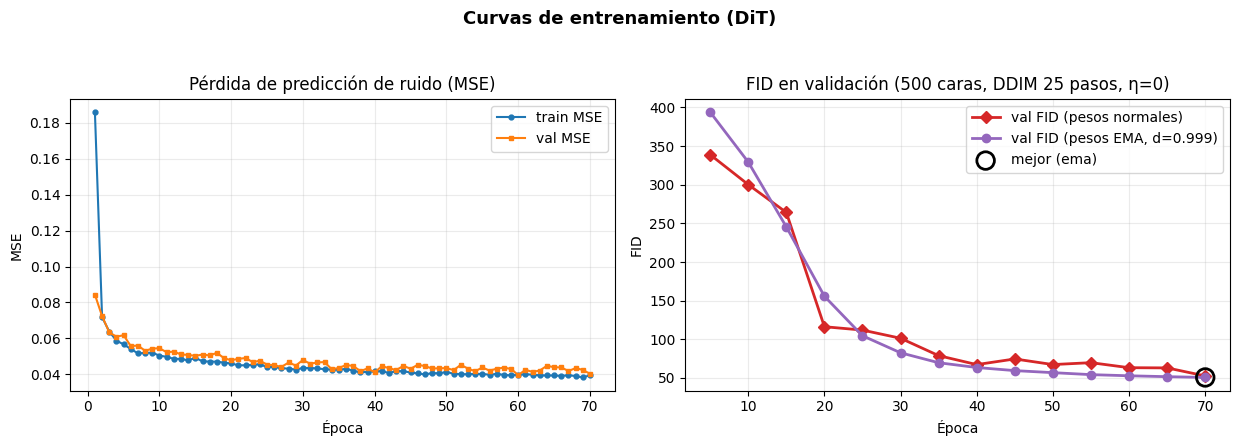

Resumen validación: mejor val_fid en época 70 (50.62, pesos ema) | mejor val_loss en época 60 (0.03951) | tiempo medio/época: 199.2s | total: 232.4 min


In [26]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Intentar recuperar 'history' desde el archivo guardado en Google Drive si no existe en memoria
if "history" not in globals() and "HISTORY_PATH" in globals() and HISTORY_PATH.exists():
    try:
        history = json.loads(HISTORY_PATH.read_text())
        print(f"Historial recuperado desde: {HISTORY_PATH.name}")
    except Exception as e:
        print(f"No se pudo cargar el historial desde el archivo: {e}")

if "history" not in globals():
    raise NameError("La variable 'history' no está definida y no se encontró el archivo de historial en Drive. Por favor, asegúrate de que exista el archivo de checkpoint o ejecuta la celda de entrenamiento primero.")

epochs_axis = np.arange(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

axes[0].plot(epochs_axis, history["loss"], marker="o", markersize=3.5, label="train MSE")
axes[0].plot(epochs_axis, history["val_loss"], marker="s", markersize=3.5, label="val MSE")
axes[0].set_title("Pérdida de predicción de ruido (MSE)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE")
axes[0].grid(alpha=0.25)
axes[0].legend()

if history.get("val_fid_epochs"):
    axes[1].plot(history["val_fid_epochs"], history["val_fid_scores"], marker="D", color="tab:red",
                 linewidth=2, label="val FID (pesos normales)")
    axes[1].plot(history["val_fid_epochs"], history["val_fid_ema_scores"], marker="o", color="tab:purple",
                 linewidth=2, label=f"val FID (pesos EMA, d={EMA_DECAY})")
    axes[1].scatter([history["best_val_fid_epoch"]], [history["best_val_fid"]], s=160, facecolors="none",
                    edgecolors="black", linewidths=2, zorder=5, label=f"mejor ({history['best_kind']})")
    axes[1].set_title(f"FID en validación (500 caras, DDIM {history.get('val_ddim_steps', VAL_DDIM_STEPS)} pasos, η=0)")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("FID")
    axes[1].grid(alpha=0.25)
    axes[1].legend()
else:
    axes[1].axis("off")

plt.suptitle("Curvas de entrenamiento (DiT)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(CHECKPOINT_DIR / "dit_training_curves.png", dpi=140, bbox_inches="tight")
plt.show()

best_mse_ep = int(np.argmin(history["val_loss"])) + 1
train_minutes = float(np.sum(history["epoch_time_s"])) / 60
print(
    f"Resumen validación: mejor val_fid en época {history['best_val_fid_epoch']} "
    f"({history['best_val_fid']:.2f}, pesos {history['best_kind']}) | "
    f"mejor val_loss en época {best_mse_ep} ({min(history['val_loss']):.5f}) | "
    f"tiempo medio/época: {np.mean(history['epoch_time_s']):.1f}s | total: {train_minutes:.1f} min"
)

---

## **6. Estudio de muestreo DDIM y selección del mejor método (sin reentrenar)**

Con los mismos pesos ya entrenados (`100` épocas con el objetivo estándar de DDPM, $T = 1000$) ajustamos el muestreador DDIM sin reentrenar nada. Como en la U-Net, entrenar con DDPM permite muestrear con DDIM: ambos comparten las mismas distribuciones marginales $q(x_t \mid x_0)$, así que el predictor de ruido $\epsilon_\theta(x_t, x_{\text{mask}}, t)$ es el mismo.

En cada salto $t \to t_{\text{prev}}$ se estima primero la cara limpia $\hat{x}_0$ y se calcula

$$x_{t_{\text{prev}}} = \sqrt{\bar{\alpha}_{t_{\text{prev}}}}\,\hat{x}_0 + \sqrt{1 - \bar{\alpha}_{t_{\text{prev}}} - \sigma_t^2}\,\hat{\epsilon} + \sigma_t\,z, \qquad \sigma_t = \eta\,\sqrt{\frac{1 - \bar{\alpha}_{t_{\text{prev}}}}{1 - \bar{\alpha}_t}}\sqrt{1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t_{\text{prev}}}}}$$

- **$\eta = 0$ (determinista):** la trayectoria queda fijada por el ruido inicial y un desvío temprano se arrastra hasta $t = 0$.
- **$\eta > 0$ (hasta $\eta = 1$, estocástico):** se reintroduce ruido en cada salto, lo que puede corregir pequeños errores acumulados.
- **Pasos (`steps`):** más pasos dan una trayectoria más precisa, pero cuestan más tiempo.

**Diferencia con el notebook de la U-Net:** allí se probaban primero los $\eta$ con `DDIM 50` y luego los pasos con el mejor $\eta$. Aquí se evalúa la **rejilla completa** `pasos (10, 25, 50, 100)` $\times$ `eta (0, 0.5, 1)` sobre las `500` caras cacheadas de validación, usando los **mejores pesos** del entrenamiento (normales o EMA, según el menor FID de validación). Se elige automáticamente la configuración con menor FID (`BEST_STEPS`, `BEST_ETA`) y se define `generate()`.

In [27]:
import keras

# Cargar los modelos guardados en Google Drive si no existen en memoria activa
if "dit" not in globals() or "dit_ema" not in globals():
    try:
        print("Cargando los mejores modelos guardados desde Google Drive...")
        dit = keras.models.load_model(DIT_PATH, compile=False)
        dit_ema = keras.models.load_model(DIT_EMA_PATH, compile=False)
        print("Modelos cargados correctamente.")
    except Exception as e:
        print(f"Error al intentar cargar los modelos: {e}")
        print("Asegúrate de haber montado correctamente Google Drive y que los archivos existan.")

BEST_KIND = history.get("best_kind", "normal")
FINAL_NET = dit_ema if BEST_KIND == "ema" else dit
print(
    f"Pesos usados en el estudio DDIM y en test: {BEST_KIND.upper()} "
    f"(val_fid={history['best_val_fid']:.2f} en la época {history['best_val_fid_epoch']}) | "
    f"{FINAL_NET.count_params():,} parámetros."
)

Cargando los mejores modelos guardados desde Google Drive...
Modelos cargados correctamente.
Pesos usados en el estudio DDIM y en test: EMA (val_fid=50.62 en la época 70) | 9,788,720 parámetros.


In [30]:
SAMPLING_STUDY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_sampling_study.json"

ETA_GRID = (0.0, 0.5, 1.0)
STEPS_GRID = (10, 25, 50, 100)

val_masks_study = x_val[:VAL_FID_SAMPLES]
n_batches_val = int(np.ceil(VAL_FID_SAMPLES / BATCH_SIZE))


def _canonical_label(steps: int, eta: float) -> str:
    return f"DDIM {steps} (η={eta:g})"


_study_ok = False
if SAMPLING_STUDY_PATH.exists():
    sampling_study = json.loads(SAMPLING_STUDY_PATH.read_text())
    _study_ok = (
        sampling_study.get("weights_kind") == BEST_KIND
        and sampling_study.get("best_val_fid_epoch") == history["best_val_fid_epoch"]
        and sampling_study.get("steps_grid") == list(STEPS_GRID)
        and sampling_study.get("eta_grid") == list(ETA_GRID)
    )
    if _study_ok:
        print(f"Resultados cargados de {SAMPLING_STUDY_PATH.name}")

if not _study_ok:
    all_results = []
    for steps in STEPS_GRID:
        for eta in ETA_GRID:
            label = _canonical_label(steps, eta)
            print(f"Probando {label}...", end=" ", flush=True)
            t0 = time.time()
            preds_cfg = ddim_sample(
                FINAL_NET,
                val_masks_study,
                steps=steps,
                eta=eta,
                seed=SEED,
                batch_size=BATCH_SIZE,
            )
            elapsed_s = float(time.time() - t0)
            fake_feats_cfg = extract_inception_features(denormalize_image(preds_cfg))
            v_fid = compute_fid_from_features(real_val_fid_feats, fake_feats_cfg)
            rec = {
                "label": label,
                "steps": int(steps),
                "eta": float(eta),
                "val_fid": round(v_fid, 2),
                "time_per_batch_s": round(elapsed_s / n_batches_val, 3),
                "total_time_s": round(elapsed_s, 2),
            }
            all_results.append(rec)
            print(f"FID={rec['val_fid']:.2f} ({rec['total_time_s']:.1f}s)", flush=True)

    sampling_study = {
        "weights_kind": BEST_KIND,
        "best_val_fid_epoch": history["best_val_fid_epoch"],
        "eta_grid": list(ETA_GRID),
        "steps_grid": list(STEPS_GRID),
        "all_results": all_results,
    }
    SAMPLING_STUDY_PATH.write_text(json.dumps(sampling_study, indent=2, ensure_ascii=False))
    print(f"Resultados guardados en {SAMPLING_STUDY_PATH.name}", flush=True)

# Caras fijas de validación y ruido inicial compartido para las comparativas visuales
val_vis_indices = np.array([0, 1, 2], dtype=np.int32)
val_vis_masks = x_val[val_vis_indices]
val_vis_noise = np.random.default_rng(SEED + 7).standard_normal(
    (len(val_vis_indices), IMG_SIZE, IMG_SIZE, CHANNELS)
).astype(np.float32)
_vis_cache = {}


def _get_vis_preds(steps: int, eta: float) -> np.ndarray:
    key = (int(steps), round(float(eta), 4))
    if key not in _vis_cache:
        _vis_cache[key] = ddim_sample(
            FINAL_NET,
            val_vis_masks,
            steps=steps,
            eta=eta,
            seed=SEED + 7,
            initial_noise=val_vis_noise,
            batch_size=len(val_vis_indices),
        )
    return _vis_cache[key]


def _plot_vis_comparison(col_specs: list[tuple[str, np.ndarray]], title: str):
    n_rows_v = len(val_vis_indices)
    n_cols_v = len(col_specs) + 2
    fig, axes = plt.subplots(n_rows_v, n_cols_v, figsize=(2.15 * n_cols_v, 2.25 * n_rows_v))
    for r_idx, v_idx in enumerate(val_vis_indices):
        axes[r_idx, 0].imshow(colorize_mask(x_val[v_idx]))
        axes[r_idx, 0].set_ylabel(f"ID {ids_val[v_idx]}", fontsize=9, fontweight="bold")
        axes[r_idx, 0].set_xticks([])
        axes[r_idx, 0].set_yticks([])
        if r_idx == 0:
            axes[r_idx, 0].set_title("Máscara", fontsize=9, fontweight="bold")

        for c_idx, (col_label, preds_arr) in enumerate(col_specs):
            axes[r_idx, c_idx + 1].imshow(denormalize_image(preds_arr[r_idx]))
            axes[r_idx, c_idx + 1].axis("off")
            if r_idx == 0:
                axes[r_idx, c_idx + 1].set_title(col_label, fontsize=8.5, fontweight="bold")

        axes[r_idx, -1].imshow(denormalize_image(y_val[v_idx]))
        axes[r_idx, -1].axis("off")
        if r_idx == 0:
            axes[r_idx, -1].set_title("Real", fontsize=9, fontweight="bold")

    plt.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

Resultados cargados de dit_generator_sampling_study.json


In [31]:
# Tabla resumen global y selección automática de los mejores parámetros DDIM
all_sorted = sorted(sampling_study["all_results"], key=lambda r: r["val_fid"])
summary_df = pd.DataFrame([
    {
        "Configuración": r["label"],
        "Pasos": r["steps"],
        "eta": r["eta"],
        "val_FID (500)": f"{r['val_fid']:.2f}",
        "Tiempo / lote (s)": f"{r['time_per_batch_s']:.3f}",
        "Tiempo 500 (s)": f"{r['total_time_s']:.2f}",
    }
    for r in all_sorted
])
print("Resumen de pruebas (ordenado por val_FID):")
display(summary_df)

BEST_EVAL_CFG = all_sorted[0]
BEST_STEPS = int(BEST_EVAL_CFG["steps"])
BEST_ETA = float(BEST_EVAL_CFG["eta"])
BEST_SAMPLER_LABEL = f"DDIM {BEST_STEPS} pasos, η={BEST_ETA:g}"


def generate(
    masks: np.ndarray,
    steps: int | None = None,
    eta: float | None = None,
    seed: int | None = None,
    initial_noise: np.ndarray | None = None,
    batch_size: int = BATCH_SIZE,
) -> np.ndarray:
    """Genera caras usando FINAL_NET (mejores pesos) y DDIM con los parámetros ganadores (BEST_STEPS, BEST_ETA)."""
    return ddim_sample(
        FINAL_NET,
        masks,
        steps=BEST_STEPS if steps is None else steps,
        eta=BEST_ETA if eta is None else eta,
        seed=seed,
        initial_noise=initial_noise,
        batch_size=batch_size,
    )


print(f"Mejor configuración: {BEST_SAMPLER_LABEL} (val_FID={BEST_EVAL_CFG['val_fid']:.2f}) | pesos {BEST_KIND}")

Resumen de pruebas (ordenado por val_FID):


,Configuración,Pasos,eta,val_FID (500),Tiempo / lote (s),Tiempo 500 (s)
0,DDIM 10 (η=0),10,0.0,50.06,54.779,438.23
1,DDIM 25 (η=0),25,0.0,50.62,135.194,1081.55
2,DDIM 10 (η=0.5),10,0.5,51.76,55.095,440.76
3,DDIM 100 (η=1),100,1.0,52.16,564.794,4518.36
4,DDIM 25 (η=0.5),25,0.5,52.31,134.164,1073.31
5,DDIM 50 (η=1),50,1.0,52.75,288.799,2310.39
6,DDIM 25 (η=1),25,1.0,53.68,131.723,1053.78
7,DDIM 50 (η=0),50,0.0,54.08,267.924,2143.39
8,DDIM 50 (η=0.5),50,0.5,54.13,279.699,2237.59
9,DDIM 100 (η=0.5),100,0.5,56.65,561.914,4495.31


Mejor configuración: DDIM 10 pasos, η=0 (val_FID=50.06) | pesos ema


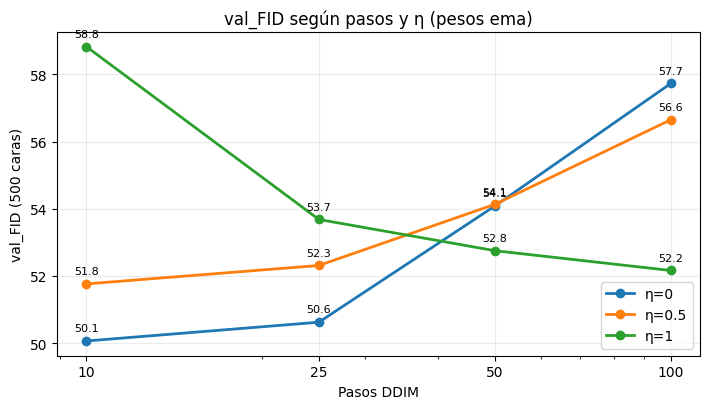

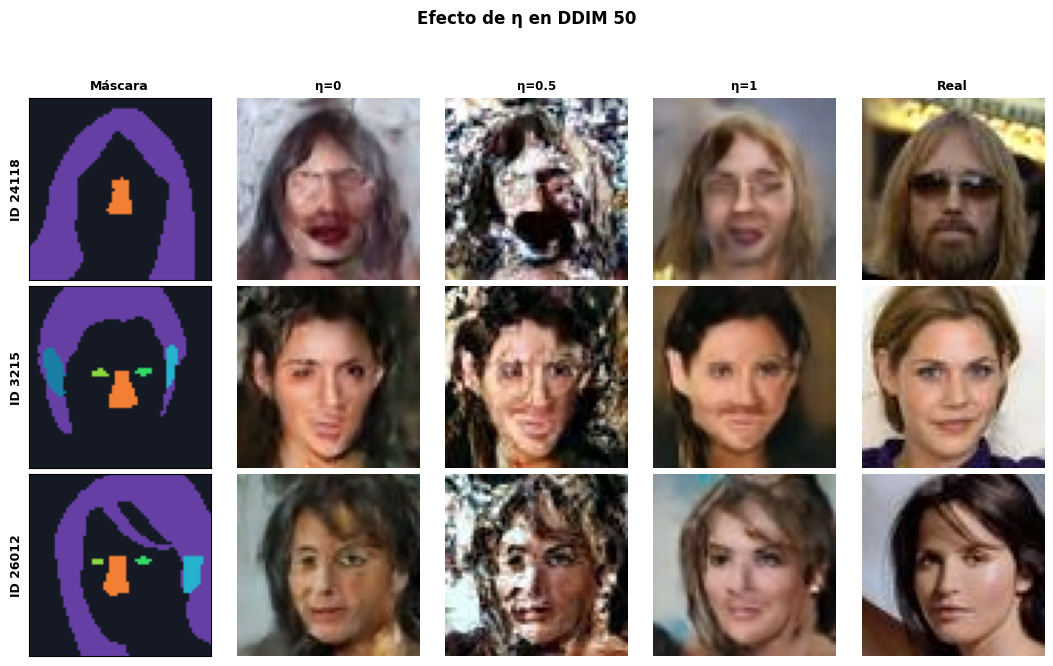

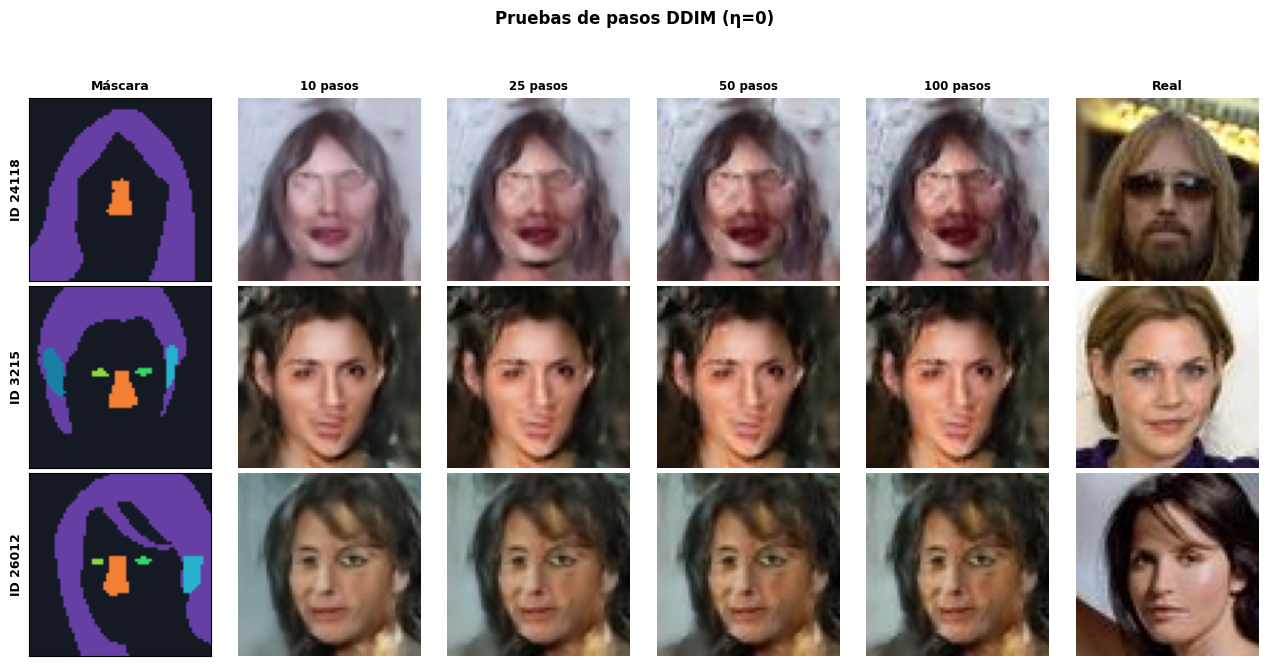

In [32]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for eta in ETA_GRID:
    recs = sorted([r for r in sampling_study["all_results"] if r["eta"] == eta], key=lambda r: r["steps"])
    ax.plot([r["steps"] for r in recs], [r["val_fid"] for r in recs], marker="o", linewidth=2, label=f"η={eta:g}")
    for r in recs:
        ax.annotate(f"{r['val_fid']:.1f}", (r["steps"], r["val_fid"]), textcoords="offset points",
                    xytext=(0, 7), ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xticks(list(STEPS_GRID))
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_title(f"val_FID según pasos y η (pesos {BEST_KIND})")
ax.set_xlabel("Pasos DDIM")
ax.set_ylabel("val_FID (500 caras)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Comparativa visual de η con DDIM 50 (mismo ruido inicial)
_plot_vis_comparison(
    [(f"η={eta:g}", _get_vis_preds(50, eta)) for eta in ETA_GRID],
    "Efecto de η en DDIM 50",
)

# Comparativa visual de pasos con el mejor η
_plot_vis_comparison(
    [(f"{st} pasos", _get_vis_preds(st, BEST_ETA)) for st in STEPS_GRID],
    f"Pruebas de pasos DDIM (η={BEST_ETA:g})",
)

---

## **7. Evaluación en `test`, diversidad y mezcla de caras**

1. **Visualización en `test`:** comparamos `Máscara`, `Generada`, `Real` y `Error |y - ŷ|` sobre ejemplos de test.
2. **Visualización de diversidad (`4` máscaras $\times$ `5` muestras):** generamos 5 caras distintas para cada máscara cambiando solo la semilla del ruido inicial $x_T$.
3. **Mezcla de caras (`mix_faces`):** combinamos atributos de `2` o `3` personas de `test`.
4. **Evaluación cuantitativa final** con la mejor configuración de muestreo de la Sección 6 sobre `3.000` muestras:
   - **Emparejado (`3.000`):** `L1 (MAE)`, `1 - SSIM`, `FID` y `KID` de $G(x_{\text{test}})$ frente a $y_{\text{test}}$.
   - **Caras nuevas (`3.000`):** caras generadas con máscaras híbridas de pares aleatorios de `test` (`random_pairs(...)`), con su `FID` y `KID`.
   - **Suelo real (`val` vs `test`, `3.000`):** FID y KID entre dos particiones reales distintas, que marcan la cota inferior alcanzable.

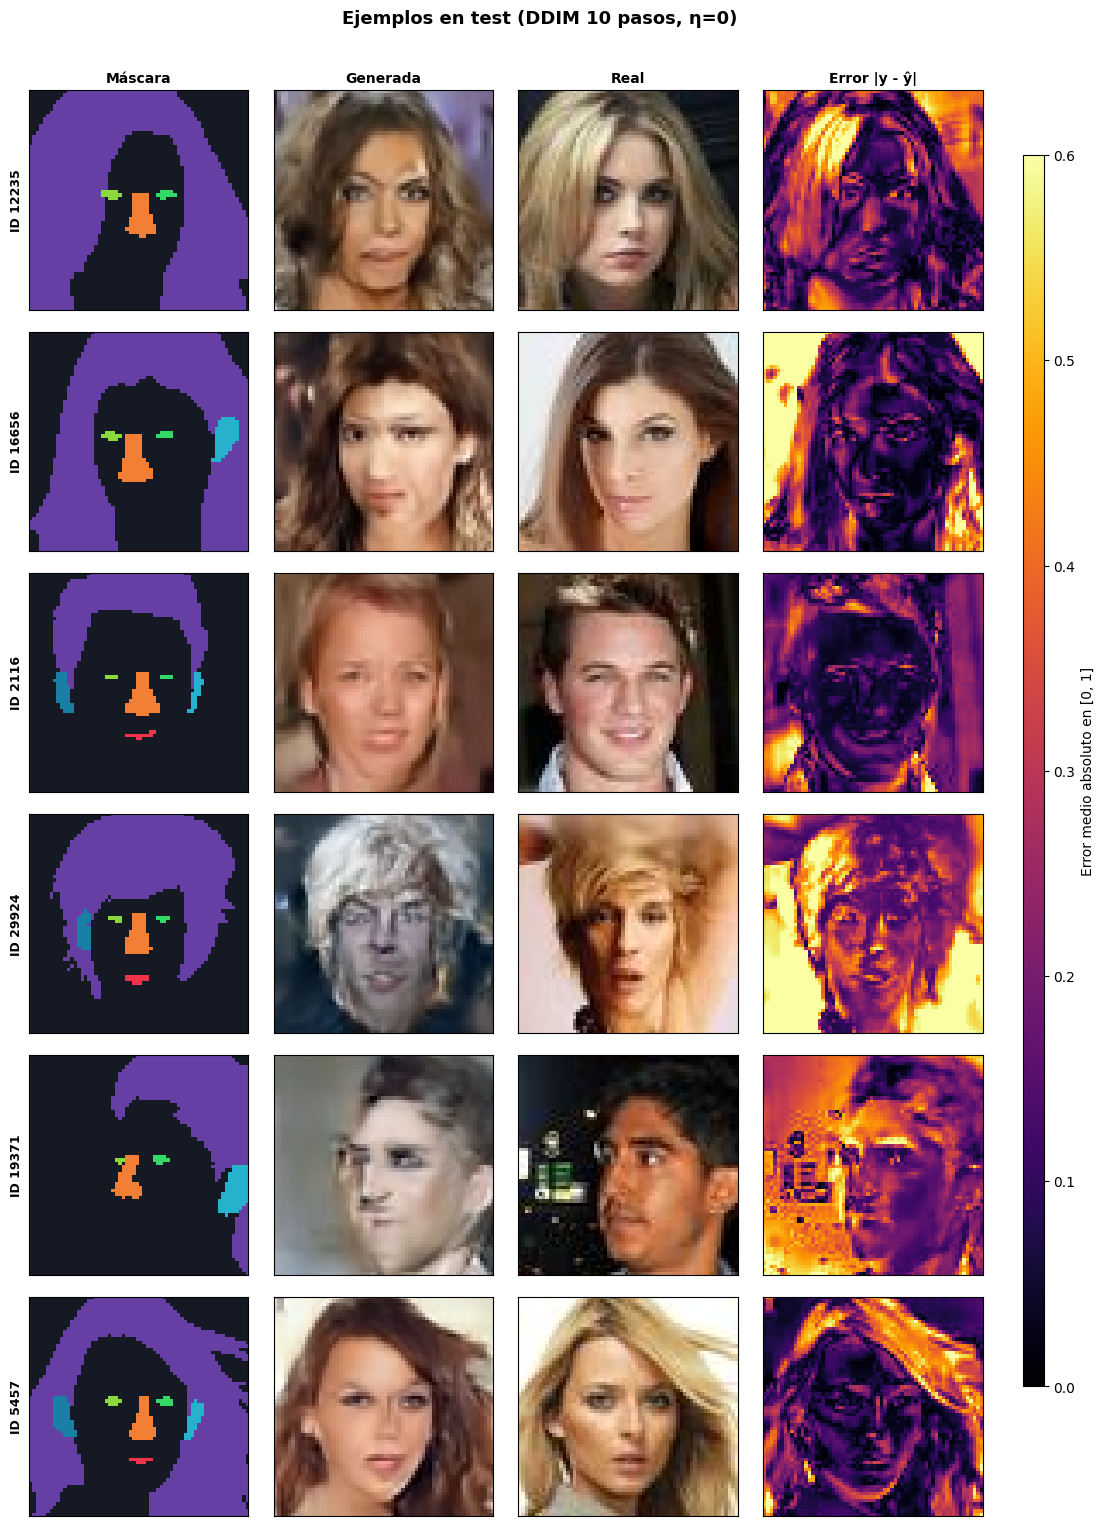

In [ ]:
qual_indices = np.random.default_rng(SEED).choice(len(x_test), size=6, replace=False)
qual_preds = generate(x_test[qual_indices], seed=SEED, batch_size=len(qual_indices))

fig, axes = plt.subplots(len(qual_indices), 4, figsize=(11.5, 2.7 * len(qual_indices)))
col_titles = ["Máscara", "Generada", "Real", "Error |y - ŷ|"]
last_im = None

for row_idx, t_idx in enumerate(qual_indices):
    gen_rgb = denormalize_image(qual_preds[row_idx])
    real_rgb = denormalize_image(y_test[t_idx])
    abs_err = np.mean(np.abs(real_rgb - gen_rgb), axis=-1)

    axes[row_idx, 0].imshow(colorize_mask(x_test[t_idx]))
    axes[row_idx, 1].imshow(gen_rgb)
    axes[row_idx, 2].imshow(real_rgb)
    last_im = axes[row_idx, 3].imshow(abs_err, cmap="inferno", vmin=0.0, vmax=0.6)
    axes[row_idx, 0].set_ylabel(f"ID {ids_test[t_idx]}", fontsize=9, fontweight="bold")
    for c_idx in range(4):
        if row_idx == 0:
            axes[row_idx, c_idx].set_title(col_titles[c_idx], fontsize=10, fontweight="bold")
        axes[row_idx, c_idx].set_xticks([])
        axes[row_idx, c_idx].set_yticks([])

cbar_ax = fig.add_axes([0.92, 0.12, 0.018, 0.76])
fig.colorbar(last_im, cax=cbar_ax, label="Error medio absoluto en [0, 1]")
fig.suptitle(f"Ejemplos en test ({BEST_SAMPLER_LABEL})", fontsize=13, fontweight="bold", y=0.97)
fig.subplots_adjust(left=0.05, right=0.89, top=0.92, bottom=0.04, hspace=0.10, wspace=0.06)
fig.savefig(CHECKPOINT_DIR / "dit_test_grid.png", dpi=140, bbox_inches="tight")
plt.show()

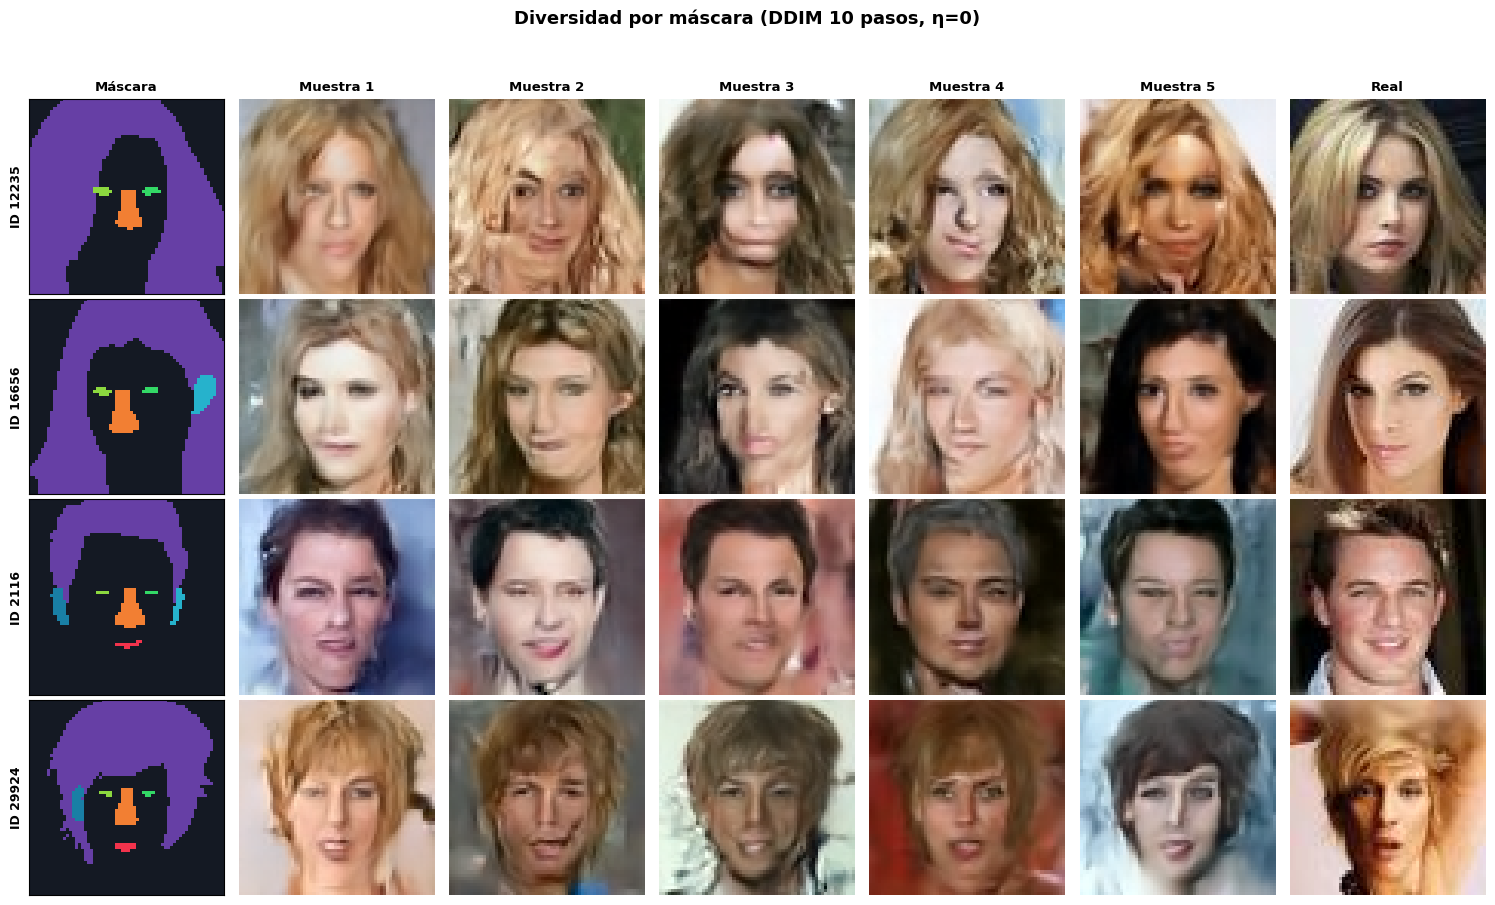

In [ ]:
div_indices = qual_indices[:4]
n_variants = 5
div_masks = x_test[div_indices]

variant_batches = [
    generate(div_masks, seed=SEED + 100 + v_idx, batch_size=len(div_indices))
    for v_idx in range(n_variants)
]

fig, axes = plt.subplots(len(div_indices), n_variants + 2, figsize=(2.15 * (n_variants + 2), 2.3 * len(div_indices)))
for r_idx, t_idx in enumerate(div_indices):
    axes[r_idx, 0].imshow(colorize_mask(x_test[t_idx]))
    axes[r_idx, 0].set_ylabel(f"ID {ids_test[t_idx]}", fontsize=9, fontweight="bold")
    axes[r_idx, 0].set_xticks([])
    axes[r_idx, 0].set_yticks([])
    if r_idx == 0:
        axes[r_idx, 0].set_title("Máscara", fontsize=9.5, fontweight="bold")

    for v_idx in range(n_variants):
        axes[r_idx, v_idx + 1].imshow(denormalize_image(variant_batches[v_idx][r_idx]))
        axes[r_idx, v_idx + 1].axis("off")
        if r_idx == 0:
            axes[r_idx, v_idx + 1].set_title(f"Muestra {v_idx + 1}", fontsize=9.5, fontweight="bold")

    axes[r_idx, -1].imshow(denormalize_image(y_test[t_idx]))
    axes[r_idx, -1].axis("off")
    if r_idx == 0:
        axes[r_idx, -1].set_title("Real", fontsize=9.5, fontweight="bold")

plt.suptitle(f"Diversidad por máscara ({BEST_SAMPLER_LABEL})", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

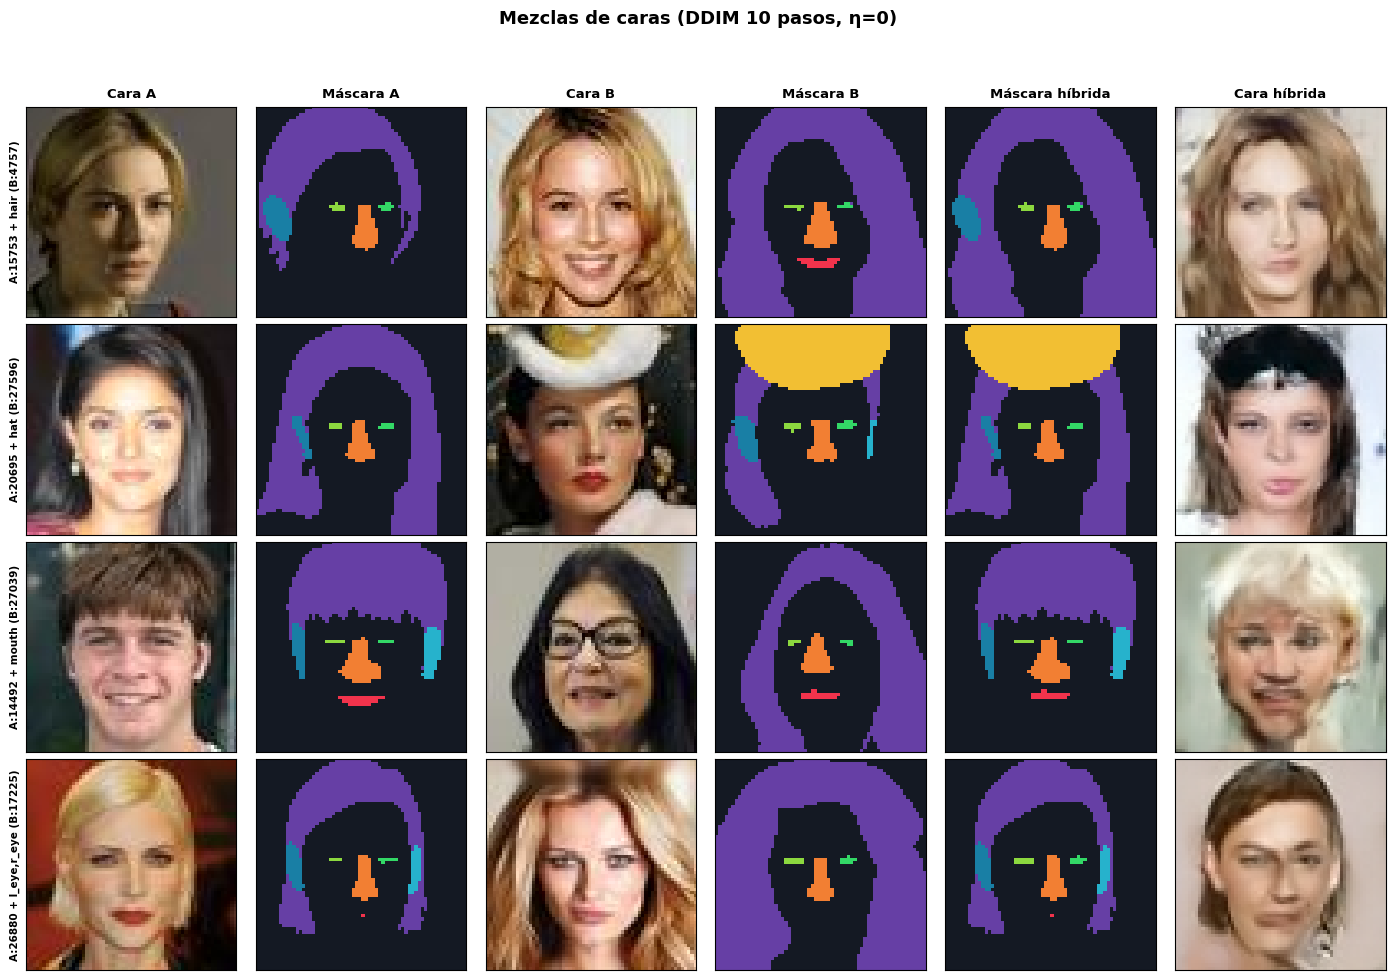

(array([[[[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         ...,
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [1., 0., 0., ..., 0., 0., 0.],
          [1.

In [34]:
SPLIT_STORE = {
    "test": (x_test, y_test, ids_test),
    "val": (x_val, y_val, ids_val),
}

DEFAULT_ATTRS_OPTIONS = [
    ["hair"],
    ["hat"],
    ["mouth"],
    ["l_eye", "r_eye"],
    ["hair", "hat"],
    ["l_ear", "r_ear"],
    ["nose"],
]

GRID_PAIRS = [
    (1387, 378, ["hair"]),
    (1277, 745, ["hat"]),
    (1363, 344, ["mouth"]),
    (1816, 1900, ["l_eye", "r_eye"]),
]


def _resolve_split_index(idx_or_id, ids_arr: np.ndarray) -> int:
    if isinstance(idx_or_id, str):
        matches = np.where(ids_arr == idx_or_id)[0]
        if len(matches) == 0:
            raise ValueError(f"ID '{idx_or_id}' no encontrado en el split.")
        return int(matches[0])
    idx = int(idx_or_id)
    if 0 <= idx < len(ids_arr):
        return idx
    matches = np.where(ids_arr == str(idx))[0]
    if len(matches) > 0:
        return int(matches[0])
    raise IndexError(f"Índice o ID {idx_or_id} fuera de rango para split de tamaño {len(ids_arr)}.")


def hybridize_masks(
    mask_a: np.ndarray,
    mask_b: np.ndarray,
    attrs_from_b: list[str],
    mask_classes: list[str] = MASK_CLASSES,
) -> np.ndarray:
    """Combina mask_a reemplazando los canales indicados con los de mask_b."""
    hybrid = mask_a.copy()
    for attr in attrs_from_b:
        if attr in mask_classes:
            c_idx = mask_classes.index(attr)
            hybrid[:, :, c_idx] = mask_b[:, :, c_idx]
    return hybrid


def random_pairs(
    n_pairs: int,
    seed: int,
    n_total: int | None = None,
    attrs_options: list[list[str]] = DEFAULT_ATTRS_OPTIONS,
    split: str = "test",
) -> list[tuple[int, int, list[str]]]:
    """Genera pares aleatorios de máscaras y atributos (reproducible por semilla)."""
    if n_total is None:
        n_total = len(SPLIT_STORE[split][0])
    rng = np.random.default_rng(seed)
    options = [opt for opt in ([a for a in o if a in MASK_CLASSES] for o in attrs_options) if opt]
    return [
        (ia, (ia + 1 + int(rng.integers(n_total - 1))) % n_total, options[int(rng.integers(len(options)))])
        for ia in rng.integers(n_total, size=n_pairs).tolist()
    ]


def mix_faces(
    recipes: list[tuple[int | str, list[tuple[int | str, list[str]]]]],
    split: str = "test",
    seed: int = SEED,
    steps: int | None = None,
    eta: float | None = None,
    save_path: Path | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Mezcla atributos de 2 o 3 personas según una lista de recetas y dibuja el resultado."""
    x_s, y_s, ids_s = SPLIT_STORE[split]
    resolved_recipes = []
    hybrid_list = []

    for base_raw, donors_raw in recipes:
        i_base = _resolve_split_index(base_raw, ids_s)
        hybrid_mask = x_s[i_base].copy()
        resolved_donors = []
        for donor_raw, attrs_raw in donors_raw:
            i_donor = _resolve_split_index(donor_raw, ids_s)
            attrs = [a for a in attrs_raw if a in MASK_CLASSES]
            hybrid_mask = hybridize_masks(hybrid_mask, x_s[i_donor], attrs)
            resolved_donors.append((i_donor, attrs))
        resolved_recipes.append((i_base, resolved_donors))
        hybrid_list.append(hybrid_mask)

    hybrid_masks = np.stack(hybrid_list, axis=0)
    hybrid_faces = generate(hybrid_masks, steps=steps, eta=eta, seed=seed)

    max_donors = max(len(donors) for _, donors in resolved_recipes)
    n_rows = len(resolved_recipes)
    n_cols = 2 * (1 + max_donors) + 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.35 * n_cols, 2.45 * n_rows), squeeze=False)

    person_letters = [chr(ord("A") + k) for k in range(1 + max_donors)]
    headers = []
    for letter in person_letters:
        headers += [f"Cara {letter}", f"Máscara {letter}"]
    headers += ["Máscara híbrida", "Cara híbrida"]

    for row_idx, (i_base, donors) in enumerate(resolved_recipes):
        panels = [
            denormalize_image(y_s[i_base]),
            colorize_mask(x_s[i_base]),
        ]
        ylabel_parts = [f"A:{ids_s[i_base]}"]
        for d_idx, (i_donor, attrs) in enumerate(donors):
            letter = chr(ord("B") + d_idx)
            panels += [
                denormalize_image(y_s[i_donor]),
                colorize_mask(x_s[i_donor]),
            ]
            ylabel_parts.append(f"{','.join(attrs)} ({letter}:{ids_s[i_donor]})")
        panels += [
            colorize_mask(hybrid_masks[row_idx]),
            denormalize_image(hybrid_faces[row_idx]),
        ]

        for col_idx in range(n_cols):
            ax = axes[row_idx, col_idx]
            if col_idx < len(panels):
                ax.imshow(panels[col_idx])
                if row_idx == 0:
                    ax.set_title(headers[col_idx], fontsize=9.5, fontweight="bold")
                if col_idx == 0:
                    ax.set_ylabel(" + ".join(ylabel_parts), fontsize=7.5, fontweight="bold")
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                ax.axis("off")

    fig.suptitle(f"Mezclas de caras ({BEST_SAMPLER_LABEL})", fontsize=13, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if save_path is not None:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()
    return hybrid_masks, hybrid_faces


mix_faces(
    [(ia, [(ib, attrs)]) for ia, ib, attrs in GRID_PAIRS],
    seed=SEED + 22,
    save_path=CHECKPOINT_DIR / "dit_mix_grid.png",
)

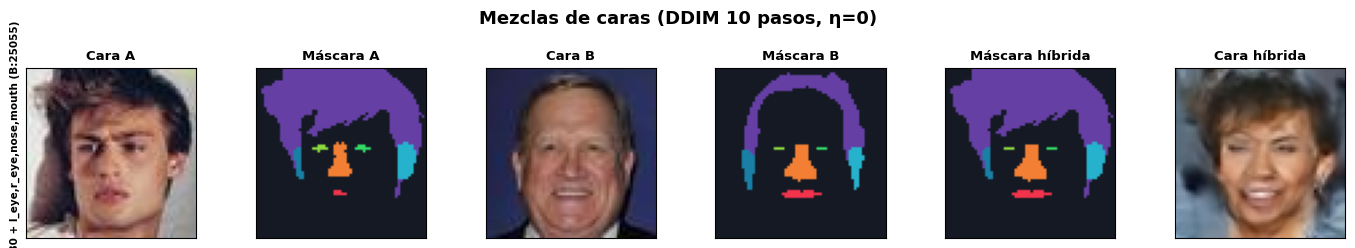

(array([[[[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         ...,
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0.

In [ ]:
# Ejemplo de mezcla de 2 personas
mix_faces([(20, [(30, ["l_eye", "r_eye", "nose", "mouth"])])])

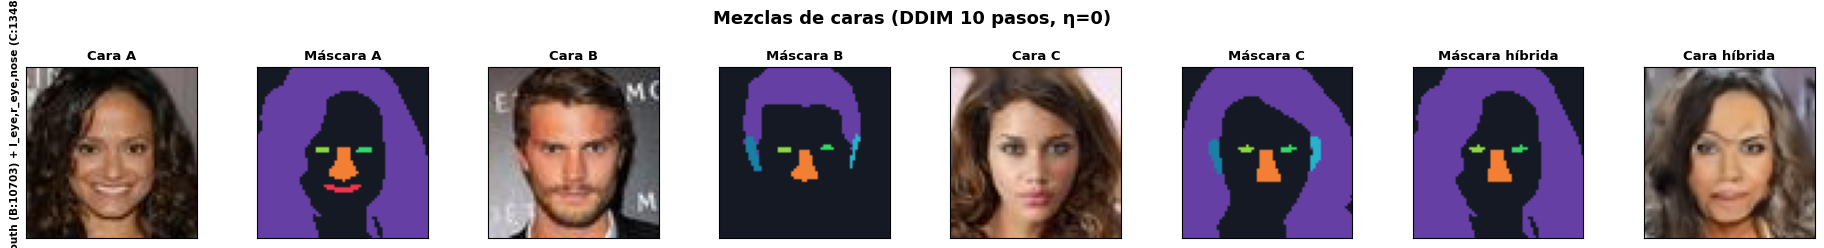

(array([[[[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         ...,
 
         [[1., 0., 0., ..., 0., 0., 0.],
          [1., 0., 0., ..., 0., 0., 0.],
          [1., 0., 0., ..., 0., 0., 0.],
          ...,
          [1., 0., 0., ..., 0., 0., 0.],
          [1.

In [ ]:
# Ejemplo de mezcla de 3 personas
mix_faces([(10, [(71, ["mouth"]), (84, ["l_eye", "r_eye", "nose"])])])

### **7.1 Evaluación cuantitativa final**

In [35]:
FORCE_EVAL = False

def compute_kid_from_features(
    real_feats: torch.Tensor,
    fake_feats: torch.Tensor,
    subsets: int = 100,
    subset_size: int = 1000,
    seed: int = SEED,
) -> tuple[float, float]:
    """Calcula KID (media y desviación típica) sobre características InceptionV3."""
    n_r, d = real_feats.shape
    n_f = fake_feats.shape[0]
    m = min(int(subset_size), n_r, n_f)

    k_rr = ((real_feats @ real_feats.T) / d + 1.0) ** 3
    k_ff = ((fake_feats @ fake_feats.T) / d + 1.0) ** 3
    k_rf = ((real_feats @ fake_feats.T) / d + 1.0) ** 3

    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(int(subsets)):
        idx_r = torch.from_numpy(rng.choice(n_r, size=m, replace=False))
        idx_f = torch.from_numpy(rng.choice(n_f, size=m, replace=False))
        sub_rr = k_rr[idx_r][:, idx_r]
        sub_ff = k_ff[idx_f][:, idx_f]
        sub_rf = k_rf[idx_r][:, idx_f]
        sum_rr = sub_rr.sum() - sub_rr.diagonal().sum()
        sum_ff = sub_ff.sum() - sub_ff.diagonal().sum()
        mmd2 = (sum_rr + sum_ff) / (m * (m - 1)) - 2.0 * sub_rf.mean()
        vals.append(float(mmd2.item()))
    arr = np.asarray(vals, dtype=np.float64)
    return float(arr.mean()), float(arr.std())


def evaluate_diffusion_model() -> pd.DataFrame:
    y_test_pred = generate(x_test, seed=SEED)

    y_test_01 = denormalize_image(y_test)
    y_val_01 = denormalize_image(y_val)
    paired_01 = denormalize_image(y_test_pred)

    l1_mae = float(np.mean(np.abs(y_test_01 - paired_01)))
    one_minus_ssim = 1.0 - float(
        tf.reduce_mean(
            tf.image.ssim(
                tf.convert_to_tensor(y_test_01, dtype=tf.float32),
                tf.convert_to_tensor(paired_01, dtype=tf.float32),
                max_val=1.0,
            )
        ).numpy()
    )

    feats_real_test = extract_inception_features(y_test_01)
    feats_real_val = extract_inception_features(y_val_01)
    feats_paired = extract_inception_features(paired_01)

    fid_paired = compute_fid_from_features(feats_real_test, feats_paired)
    floor_fid = compute_fid_from_features(feats_real_test, feats_real_val)
    kid_paired_mean, kid_paired_std = compute_kid_from_features(feats_real_test, feats_paired, seed=SEED)
    floor_kid_mean, floor_kid_std = compute_kid_from_features(feats_real_test, feats_real_val, seed=SEED)

    new_pairs = random_pairs(n_pairs=NEW_FACES_N, seed=SEED + 2025)
    x_new_masks = np.stack(
        [hybridize_masks(x_test[ia], x_test[ib], attrs) for ia, ib, attrs in new_pairs],
        axis=0,
    )
    new_faces_01 = denormalize_image(generate(x_new_masks, seed=SEED + 2025))
    feats_new = extract_inception_features(new_faces_01)
    fid_new = compute_fid_from_features(feats_real_test, feats_new)
    kid_new_mean, kid_new_std = compute_kid_from_features(feats_real_test, feats_new, seed=SEED + 2025)

    rows = [
        {
            "Modelo": NOTEBOOK_NAME,
            "L1 (MAE)": f"{l1_mae:.4f}",
            "1 - SSIM": f"{one_minus_ssim:.4f}",
            "FID emparejado (3k)": f"{fid_paired:.2f}",
            "FID caras nuevas (3k)": f"{fid_new:.2f}",
            "KID emparejado (3k)": f"{kid_paired_mean:.4f} ± {kid_paired_std:.4f}",
            "KID caras nuevas (3k)": f"{kid_new_mean:.4f} ± {kid_new_std:.4f}",
        },
        {
            "Modelo": "Suelo real (val vs test)",
            "L1 (MAE)": "-",
            "1 - SSIM": "-",
            "FID emparejado (3k)": f"{floor_fid:.2f}",
            "FID caras nuevas (3k)": f"{floor_fid:.2f}",
            "KID emparejado (3k)": f"{floor_kid_mean:.4f} ± {floor_kid_std:.4f}",
            "KID caras nuevas (3k)": f"{floor_kid_mean:.4f} ± {floor_kid_std:.4f}",
        },
    ]
    return pd.DataFrame(rows)


_cached_ok = False
if not TRAIN_MODEL and not FORCE_EVAL and METRICS_CSV_PATH.exists():
    _tmp_df = pd.read_csv(METRICS_CSV_PATH)
    if "KID emparejado (3k)" in _tmp_df.columns and "KID caras nuevas (3k)" in _tmp_df.columns:
        metrics_df = _tmp_df
        _cached_ok = True

if _cached_ok:
    print(f"Métricas cargadas de {METRICS_CSV_PATH.name}:")
    display(metrics_df)
else:
    metrics_df = evaluate_diffusion_model()
    metrics_df.to_csv(METRICS_CSV_PATH, index=False)
    print(f"Evaluación completada ({BEST_SAMPLER_LABEL}) y guardada en {METRICS_CSV_PATH.name}:")
    display(metrics_df)

Evaluación completada (DDIM 10 pasos, η=0) y guardada en dit_generator_metrics.csv:


,Modelo,L1 (MAE),1 - SSIM,FID emparejado (3k),FID caras nuevas (3k),KID emparejado (3k),KID caras nuevas (3k)
0,dit_generator,0.2364,0.6776,30.52,31.22,0.0192 ± 0.0007,0.0200 ± 0.0007
1,Suelo real (val vs test),-,-,7.63,7.63,-0.0000 ± 0.0001,-0.0000 ± 0.0001


---

### **Referencias**

- W. Peebles y S. Xie. *Scalable Diffusion Models with Transformers (DiT)*. ICCV, 2023. Código oficial: <https://github.com/facebookresearch/DiT> 
- A. Dosovitskiy et al. *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT)*. ICLR, 2021.
